# Record repair and blind novelty re-check: a runnable demo of `eval.py`

This notebook runs the evaluation script `eval.py` of artifact **art_aRTQM6CQ0Dre** (iteration 6, Step 0 of the project *prompt bans substitute, not just subtract*). The script generates nothing with a model. It recomputes, from rows that earlier experiments wrote to disk, every number that a record repair of the project's report touches. Each change to the report is written as a verbatim `old_text` → `new_text` **correction**, and every value in it carries a status (MATCH / CORRECTED / NEW / CARRIED) and a source `<artifact_id>:<path>`.

**The research setting.** Ask an instruction-tuned model (Qwen3-8B, Gemma-3) for an open-ended program, such as "implement a path search", and it writes its default algorithm (BFS, Dijkstra). Ban that default in the prompt, or add a random *plan-noise* direction to the hidden states of the task specification, and it moves to another algorithm. The record makes three claims about these moves. This evaluation re-checks them:

| Stage | Question | Full-run headline |
|-|-|-|
| **0a** engine and dose | Do the 8-bit (FP8 W8A8) plan-noise effects replicate under bf16 once both engines are put on one dose unit and one share definition? | connected components: 1/50 bf16 vs 30/50 FP8 correct programs off the default at alpha 2 (Fisher p 7.2e-11), bracket p 0.056, so it *did NOT replicate in bf16* (same for shortest path) |
| **0b** landings | When a push moves the model, does it land on the base model's runner-up? | 17 of 21 events (Poisson-binomial p 5.8e-7), but only 5/8 (p 0.053) on the unconfounded held-out events, so the claim moves to the descriptive results |
| **0c** movability | Does the base model's off-default share beta predict which tasks a push moves? | Spearman 0.146 over 13 new units, 95% [-0.44, 0.65]; power 0.63 at a true 0.6; only the runtime merit R6 tracks movability (rho 0.71, Holm p 0.021) |
| **0d / 0e** | Missing tables and minor fixes | Table 206 phrasing columns, P15/P20 prices, Table 203b, Table 126c rows; plan noise vs matched decoding 19:3, but 13:0 of it on kth smallest |
| 0f | A second blind novelty adjudication of 14 disputed programs by two new LLM judges | 0 novel (not run here; see the note before the results) |

**What runs here.** This notebook runs the original code of stages s0 and 0a–0e, unchanged except that the resampling sizes move into a config cell. Their inputs come from `mini_demo_data.json`, which holds trimmed copies of the files that these stages read in nine other artifacts. With the config at the script's own values, the notebook reproduces the full run's numbers for 0a, 0b, 0c and 0e exactly. In 0d, only the values derived from the slot bootstrap differ: the P15/P20 intervals of Table 207b and the share of replicates that reach each level. The bundle ships 200 of the 2,000 replicates.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT on Colab, always install (version pinned by the artifact)
_pip('loguru==0.7.3')

# numpy, scipy, matplotlib — pre-installed on Colab, install locally only (Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

import argparse
import gc
import json
import math
import resource
import subprocess
import sys
import time
from collections import Counter
from pathlib import Path

import numpy as np
from loguru import logger

# eval.py imports its two helper modules here:
#     from src import common as C
#     from src import xstats as X
# The notebook writes those modules to demo_ws/src/ further down (with %%writefile), so these two imports run there.

# Notebook additions: environment variables for src/common.py, plots and the results printout.
import os
import textwrap
import matplotlib.pyplot as plt
from IPython.display import Image, display

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_jSassd-YWLVC/round-6/evaluation-5/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
print(f"{len(data['inputs'])} input files from {len(data['source_artifacts'])} artifacts; report excerpt "
      f"{data['report']['n_lines_kept']} of {data['report']['n_lines']} lines")
for aid, v in data["source_artifacts"].items():
    print(f"  {aid}: {v['role']}")

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
45 input files from 9 artifacts; report excerpt 141 of 5173 lines
  art_8WbrpoEFslk9: panel A: six new tasks plus a reserve extension (Qwen3-8B, bf16)
  art_9a8LrIv2lHbV: panel B: seven more new tasks (Qwen3-8B, bf16)
  art_CcZLW-9NX00l: transplant experiment: base repertoire, screen check (iteration 5)
  art_SHaWv77P1XCI: site / escape-fraction experiment (iteration 4)
  art_hG0QPiaIPNhP: Gemma replication (gemma-3-4b pt / it)
  art_jR6Pyy3W9xum: bf16 knob experiment (iteration 5)
  art_mWn-MQEnNelg: 8-bit (HF-FP8-W8A8) plan-noise experiment (iteration 4)
  art_mgek9PfVBNbh: iteration-5 evaluation (Table 174 dose units)
  art_sV0cQ3ef1ZRQ: iteration-4 evaluation (knob table, frozen screen)


## Config

`eval.py` takes three command-line flags (`--n-boot`, `--n-power`, `--max-usd`). Its other resampling sizes are written into the stage functions. All of them are collected here, and the stage code below reads these names in place of the literals. The comments give the script's own value.

Each count sets only the Monte Carlo resolution of a resampled quantity: a permutation p-value, a bootstrap interval, a power estimate, or a rarefied Hill-1 mean. The exact statistics do not depend on any of them. Those are the counts and shares, the Fisher, McNemar and Poisson-binomial p-values, Spearman rho, and every Fisher-z interval.

In [5]:
# ---- Resampling sizes (eval.py's own value in brackets) ----
N_BOOT = 10_000          # [10000] --n-boot: unit bootstrap of rho(beta, E) and of the rival deltas (stage 0c)
N_POWER = 10_000         # [10000] --n-power: Gaussian-copula replicates for the power at a true rho of 0.6 (stage 0c)
N_POWER_SMALL = 2_000    # [2000] replicates for the power at rho 0.4 / 0.8 (floor) and for the n-for-0.8 curve (stage 0c)
N_POWER_CURVE_PERM = 1_000  # [1000] permutations per replicate in the n-for-0.8 curve (stage 0c)
N_PERM_MAIN = 1_000_000  # [1_000_000] Monte Carlo permutations of the registered one-sided test of rho(beta, E) (stage 0c)
N_PERM = 200_000         # [200_000] permutations of the sensitivity, rival and figure Spearman tests (stages 0a, 0c)
N_PERM_LANDING = 10_000  # [10000] within-set shuffles of the base runner-ups (stage 0b)
N_BOOT_LANDING = 10_000  # [10000] event bootstrap of the base-minus-twin hit difference (stage 0b)
N_SUB_HILL = 1_000       # [1000] subsamples of the rarefied correct-only Hill-1 at depth 25 (stage 0d)
# ---- Not used by the stages this notebook runs ----
MAX_USD = 0.90           # [0.90] --max-usd: judge budget of stage 0f (see the note before the results)

## Put the inputs where `eval.py` looks for them

`eval.py` never opens a path itself. It asks `src/common.py` for `C.load_json("D27", "results/cells.json")` and similar, with a nickname for each source artifact (`D27` is `art_jR6Pyy3W9xum`, the bf16 knob experiment). `common.py` then finds that artifact's folder **by its artifact id** under the environment variable `AII_DEPS_ROOT`, and it finds the report under `AII_REPORT`.

`mini_demo_data.json` keys every input by the script's own provenance string `<artifact_id>:<path>`. This cell writes each one to `demo_ws/deps/<artifact_id>/<path>` and the report excerpt to `demo_ws/inputs/report/current_report.md`, then points the two variables there. So the original lookup code runs unchanged. `demo_ws/` stands in for the artifact's own folder: the helper modules are written into it, and everything the script writes (`results/`, `tables/`, `figures/`, `logs/`) lands there.

How the bundle was trimmed (`data["input_notes"]` lists each file):
- **Per-sample labels.** Both engines' `labels.jsonl` keep the rows of the six decisive tasks and the plan-noise and twin arms, with the 4 fields the script reads.
- **Hidden tests.** The tests of the 15 new units keep `kind` and `ref_times`.
- **Bootstrap replicates.** `bootstrap.json` keeps its first 200 replicates.
- **Source files.** The four source files keep only the lines the script greps for.
- **Report.** The report keeps every heading and every line that a correction or a check touches. All other lines are blank, so line numbers are unchanged.

Every other file is whole.

In [6]:
DEMO_WS = Path("demo_ws").resolve()      # stands in for the artifact's folder (src/, vendor/, results/, tables/, ...)
DEPS_ROOT_DIR = DEMO_WS / "deps"        # AII_DEPS_ROOT: one sub-folder per dependency artifact id

for key, content in data["inputs"].items():
    aid, rel = key.split(":", 1)        # '<artifact_id>:<path>', the script's own provenance key (C.prov)
    p = DEPS_ROOT_DIR / aid / rel
    p.parent.mkdir(parents=True, exist_ok=True)
    if rel.endswith(".jsonl"):          # stored as a list of rows
        p.write_text("".join(json.dumps(r) + "\n" for r in content))
    elif rel.endswith(".json"):         # stored parsed
        p.write_text(json.dumps(content))
    else:                               # .csv and .py files are stored as text
        p.write_text(content)

report_file = DEMO_WS / "inputs" / "report" / "current_report.md"
report_file.parent.mkdir(parents=True, exist_ok=True)
report_file.write_text(data["report"]["text"])

# src/common.py reads both variables when it is imported (a few cells down)
os.environ["AII_DEPS_ROOT"] = str(DEPS_ROOT_DIR)
os.environ["AII_REPORT"] = str(report_file)

# packages for the helper modules written by the next cells; demo_ws first on sys.path so `from src import ...` finds them
for pkg in ("src", "vendor"):
    (DEMO_WS / pkg).mkdir(parents=True, exist_ok=True)
    (DEMO_WS / pkg / "__init__.py").touch()
if str(DEMO_WS) not in sys.path:
    sys.path.insert(0, str(DEMO_WS))

print(f"wrote {len(data['inputs'])} input files under {DEPS_ROOT_DIR.relative_to(Path.cwd())}/ "
      f"and the report excerpt to {report_file.relative_to(Path.cwd())}")

wrote 45 input files under demo_ws/deps/ and the report excerpt to demo_ws/inputs/report/current_report.md


## Helper module `src/xstats.py` (verbatim)

These are the exact small-sample statistics behind every verdict. The next two cells write `eval.py`'s helper modules unchanged to `demo_ws/src/`, so that `from src import xstats as X` works as it does in the artifact. `audit/rederive.py` re-implements this module in the standard library as an independent check (not run here). The groups of functions:
- **Proportions.** Fisher's exact test, the one-sided Clopper–Pearson bound, the Katz log interval for a risk ratio, exact binomial and McNemar tests, the exact Poisson-binomial tail by convolution, and the Holm step-down.
- **Rank correlation.** Spearman with a permutation p-value, by exact enumeration when n! ≤ 2·10⁶ and by Monte Carlo above that. Fisher-z intervals with the plain, Fieller and Bonett–Wright standard errors. A unit bootstrap with percentile and BCa intervals.
- **Power.** The power of the one-sided permutation test under a Gaussian copula with the empirical margins.
- **Agreement.** Cohen's kappa, Gwet's AC1 and Fleiss' kappa, which are used only by stage 0f.

In [7]:
%%writefile demo_ws/src/xstats.py
"""Exact small-sample statistics used by eval.py (numpy/scipy). audit/rederive.py re-implements them in stdlib."""

from __future__ import annotations

import math
from itertools import combinations
from typing import Sequence

import numpy as np
from scipy import stats as st


# ----------------------------------------------------------------------------------------- proportions
def clopper_pearson(k: int, n: int, conf: float = 0.95) -> tuple[float, float]:
    if n == 0:
        return (math.nan, math.nan)
    a = 1 - conf
    lo = 0.0 if k == 0 else float(st.beta.ppf(a / 2, k, n - k + 1))
    hi = 1.0 if k == n else float(st.beta.ppf(1 - a / 2, k + 1, n - k))
    return (lo, hi)


def clopper_pearson_lower_one_sided(k: int, n: int, conf: float = 0.95) -> float:
    if k == 0:
        return 0.0
    return float(st.beta.ppf(1 - conf, k, n - k + 1))


def fisher(a: int, b: int, c: int, d: int, alternative: str = "two-sided") -> float:
    """2x2 [[a, b], [c, d]] with rows = groups, columns = (event, no event)."""
    return float(st.fisher_exact([[a, b], [c, d]], alternative=alternative)[1])


def katz_rr(k1: int, n1: int, k2: int, n2: int, conf: float = 0.95) -> dict:
    """Risk ratio (group1 / group2) with the Katz log interval; 0.5 added to every cell if any cell is zero."""
    a, b, c, d = k1, n1 - k1, k2, n2 - k2
    corr = 0.5 if min(a, b, c, d) == 0 else 0.0
    a, b, c, d = a + corr, b + corr, c + corr, d + corr
    rr = (a / (a + b)) / (c / (c + d))
    se = math.sqrt(1 / a - 1 / (a + b) + 1 / c - 1 / (c + d))
    z = float(st.norm.ppf(1 - (1 - conf) / 2))
    return {"rr": rr, "lo": math.exp(math.log(rr) - z * se), "hi": math.exp(math.log(rr) + z * se),
            "continuity_0.5": bool(corr)}


def binom_le_p(k: int, n: int, p: float) -> float:
    """P(X <= k) for X ~ Bin(n, p): exact one-sided test of a count against a rate from below."""
    return float(st.binom.cdf(k, n, p))


def mcnemar_exact(b: int, c: int) -> float:
    n = b + c
    if n == 0:
        return 1.0
    return float(min(1.0, 2 * st.binom.cdf(min(b, c), n, 0.5)))


def poisson_binomial_sf(k: int, probs: Sequence[float]) -> float:
    """P(X >= k) for a sum of independent Bernoulli(p_i), by exact convolution."""
    dist = np.array([1.0])
    for p in probs:
        dist = np.convolve(dist, [1 - p, p])
    return float(dist[k:].sum()) if k < len(dist) else 0.0


def holm(pvals: dict[str, float]) -> dict[str, float]:
    items = sorted(pvals.items(), key=lambda kv: kv[1])
    m = len(items)
    out, running = {}, 0.0
    for i, (k, p) in enumerate(items):
        running = max(running, min(1.0, (m - i) * p))
        out[k] = running
    return out


# ----------------------------------------------------------------------------------------- rank correlation
def spearman(x: Sequence[float], y: Sequence[float]) -> float:
    r = st.spearmanr(x, y).statistic
    return float(r) if np.isfinite(r) else math.nan


def _rank(a: np.ndarray) -> np.ndarray:
    return st.rankdata(a, axis=-1)


def spearman_perm_p(x: Sequence[float], y: Sequence[float], n_perm: int = 1_000_000, seed: int = 0,
                    alternative: str = "greater") -> dict:
    """Permutation p for Spearman with ties (mid-ranks). Exact enumeration when n! <= 2e6, else Monte Carlo."""
    x = np.asarray(x, float)
    y = np.asarray(y, float)
    n = len(x)
    rx, ry = _rank(x), _rank(y)
    obs = spearman(x, y)
    if math.factorial(n) <= 2_000_000:
        from itertools import permutations
        perms = np.array(list(permutations(range(n))))
        method = "exact enumeration"
    else:
        rng = np.random.default_rng(seed)
        perms = np.argsort(rng.random((n_perm, n)), axis=1)
        method = f"Monte Carlo, {n_perm} permutations"
    ryp = ry[perms]
    rxc = rx - rx.mean()
    rypc = ryp - ryp.mean(axis=1, keepdims=True)
    den = np.sqrt((rxc ** 2).sum() * (rypc ** 2).sum(axis=1))
    rho = np.where(den > 0, (rypc * rxc).sum(axis=1) / np.where(den > 0, den, 1), 0.0)
    eps = 1e-12
    if alternative == "greater":
        p = float((rho >= obs - eps).mean())
    elif alternative == "less":
        p = float((rho <= obs + eps).mean())
    else:
        p = float((np.abs(rho) >= abs(obs) - eps).mean())
    if method.startswith("Monte"):
        p = (p * len(perms) + 1) / (len(perms) + 1)
    return {"rho": obs, "p": p, "method": method, "alternative": alternative}


def fisher_z_ci(r: float, n: int, se_kind: str = "plain", conf: float = 0.95) -> tuple[float, float]:
    z = math.atanh(max(min(r, 0.999999), -0.999999))
    if se_kind == "plain":
        se = 1 / math.sqrt(n - 3)
    elif se_kind == "fieller":
        se = math.sqrt(1.06 / (n - 3))
    elif se_kind == "bonett_wright":
        se = math.sqrt((1 + r * r / 2) / (n - 3))
    else:
        raise ValueError(se_kind)
    q = float(st.norm.ppf(1 - (1 - conf) / 2))
    return (math.tanh(z - q * se), math.tanh(z + q * se))


def bootstrap_spearman(x: Sequence[float], y: Sequence[float], n_boot: int = 10_000, seed: int = 0) -> dict:
    """Unit bootstrap: percentile and BCa intervals; degenerate resamples (constant margin) are dropped."""
    x = np.asarray(x, float)
    y = np.asarray(y, float)
    n = len(x)
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, n, size=(n_boot, n))
    vals = np.array([_spearman_fast(x[i], y[i]) for i in idx])
    ok = np.isfinite(vals)
    v = vals[ok]
    obs = spearman(x, y)
    pct = (float(np.quantile(v, 0.025)), float(np.quantile(v, 0.975)))
    # BCa
    z0 = float(st.norm.ppf(max(min((v < obs).mean() + 0.5 * (v == obs).mean(), 1 - 1e-9), 1e-9)))
    jack = np.array([spearman(np.delete(x, i), np.delete(y, i)) for i in range(n)])
    jack = jack[np.isfinite(jack)]
    jm = jack.mean()
    num = ((jm - jack) ** 3).sum()
    den = 6 * (((jm - jack) ** 2).sum()) ** 1.5
    a = float(num / den) if den > 0 else 0.0
    out = []
    for q in (0.025, 0.975):
        zq = float(st.norm.ppf(q))
        adj = st.norm.cdf(z0 + (z0 + zq) / (1 - a * (z0 + zq)))
        out.append(float(np.quantile(v, min(max(adj, 0.0), 1.0))))
    return {"n_boot": n_boot, "n_valid": int(ok.sum()), "percentile": pct, "bca": tuple(out), "z0": z0, "a": a,
            "samples": vals}


def _spearman_fast(a: np.ndarray, b: np.ndarray) -> float:
    if np.all(a == a[0]) or np.all(b == b[0]):
        return math.nan
    ra, rb = _rank(a), _rank(b)
    ra = ra - ra.mean()
    rb = rb - rb.mean()
    return float((ra * rb).sum() / math.sqrt((ra ** 2).sum() * (rb ** 2).sum()))


def copula_power(x: Sequence[float], y: Sequence[float], rho_s: float, n: int, n_rep: int = 10_000,
                 alpha: float = 0.05, n_perm: int = 2000, seed: int = 0) -> dict:
    """Power of the one-sided permutation Spearman test under a Gaussian copula with empirical margins.

    Pearson r of the latent normals = 2 sin(pi * rho_s / 6); margins through the inverse empirical CDF (keeps ties).
    The permutation null is evaluated with n_perm permutations per replicate (shared permutation matrix)."""
    x = np.sort(np.asarray(x, float))
    y = np.sort(np.asarray(y, float))
    r = 2 * math.sin(math.pi * rho_s / 6)
    rng = np.random.default_rng(seed)
    cov = np.array([[1.0, r], [r, 1.0]])
    z = rng.multivariate_normal([0, 0], cov, size=(n_rep, n))
    u = st.norm.cdf(z)
    # inverse empirical CDF: ceil(u * m) - 1
    xi = np.minimum((u[..., 0] * len(x)).astype(int), len(x) - 1)
    yi = np.minimum((u[..., 1] * len(y)).astype(int), len(y) - 1)
    X, Y = x[xi], y[yi]
    perms = np.argsort(rng.random((n_perm, n)), axis=1)
    rej, rej2, n_def = 0, 0, 0
    for i in range(n_rep):
        a, b = X[i], Y[i]
        if np.all(a == a[0]) or np.all(b == b[0]):
            continue  # constant margin: test undefined, counted as non-rejection
        ra, rb = _rank(a), _rank(b)
        ra = ra - ra.mean()
        rbp = rb[perms]
        rbp = rbp - rbp.mean(axis=1, keepdims=True)
        rb0 = rb - rb.mean()
        dena = (ra ** 2).sum()
        obs = (ra * rb0).sum() / math.sqrt(dena * (rb0 ** 2).sum())
        null = (rbp * ra).sum(axis=1) / np.sqrt(dena * (rbp ** 2).sum(axis=1))
        p = ((null >= obs - 1e-12).sum() + 1) / (n_perm + 1)
        p2 = ((np.abs(null) >= abs(obs) - 1e-12).sum() + 1) / (n_perm + 1)
        n_def += 1
        rej += p <= alpha
        rej2 += p2 <= alpha
    return {"rho_s": rho_s, "pearson_latent": r, "n": n, "n_rep": n_rep, "n_defined": n_def,
            "power": rej / n_rep, "power_two_sided": rej2 / n_rep, "mc_se": math.sqrt(max(rej / n_rep * (1 - rej / n_rep), 1e-12) / n_rep)}


# ----------------------------------------------------------------------------------------- agreement
def cohen_kappa(a: Sequence[str], b: Sequence[str]) -> float:
    a, b = list(a), list(b)
    n = len(a)
    cats = sorted(set(a) | set(b))
    po = sum(x == y for x, y in zip(a, b)) / n
    pe = sum((a.count(c) / n) * (b.count(c) / n) for c in cats)
    if abs(1 - pe) < 1e-12:
        return math.nan
    return (po - pe) / (1 - pe)


def gwet_ac1(a: Sequence[str], b: Sequence[str], categories: Sequence[str] | None = None) -> float:
    a, b = list(a), list(b)
    n = len(a)
    cats = list(categories) if categories else sorted(set(a) | set(b))
    q = len(cats)
    if q < 2:
        return math.nan
    po = sum(x == y for x, y in zip(a, b)) / n
    pi = [(a.count(c) + b.count(c)) / (2 * n) for c in cats]
    pe = sum(p * (1 - p) for p in pi) / (q - 1)
    if abs(1 - pe) < 1e-12:
        return math.nan
    return (po - pe) / (1 - pe)


def fleiss_kappa(ratings: list[list[str]]) -> float:
    """ratings: one list of category labels per item (same number of raters per item)."""
    cats = sorted({c for r in ratings for c in r})
    m = len(ratings[0])
    N = len(ratings)
    if m < 2 or N == 0:
        return math.nan
    P_i, pj = [], {c: 0 for c in cats}
    for r in ratings:
        cnt = {c: r.count(c) for c in cats}
        for c in cats:
            pj[c] += cnt[c]
        P_i.append((sum(v * v for v in cnt.values()) - m) / (m * (m - 1)))
    Pbar = sum(P_i) / N
    pe = sum((v / (N * m)) ** 2 for v in pj.values())
    if abs(1 - pe) < 1e-12:
        return math.nan if abs(1 - Pbar) > 1e-12 else 1.0
    return (Pbar - pe) / (1 - pe)


def kappa_bootstrap(a: Sequence[str], b: Sequence[str], n_boot: int = 5000, seed: int = 0) -> tuple[float, float]:
    a, b = np.asarray(a), np.asarray(b)
    rng = np.random.default_rng(seed)
    vals = []
    for _ in range(n_boot):
        i = rng.integers(0, len(a), len(a))
        k = cohen_kappa(a[i].tolist(), b[i].tolist())
        if np.isfinite(k):
            vals.append(k)
    if not vals:
        return (math.nan, math.nan)
    return (float(np.quantile(vals, 0.025)), float(np.quantile(vals, 0.975)))


def wilcoxon_exact_greater(d: Sequence[float]) -> float:
    d = [x for x in d if x != 0]
    if not d:
        return math.nan
    return float(st.wilcoxon(d, alternative="greater", method="exact").pvalue)


def exact_mcnemar_one_sided(b: int, c: int) -> float:
    """P(X >= b) for X ~ Bin(b + c, 0.5): b = first forecaster right, second wrong."""
    n = b + c
    if n == 0:
        return 1.0
    return float(st.binom.sf(b - 1, n, 0.5))


def all_subsets(n: int, k: int):
    return combinations(range(n), k)

Writing demo_ws/src/xstats.py


## Helper module `src/common.py` (verbatim)

This is the shared infrastructure `eval.py` calls as `C`:
- **Dependency lookup.** `dep_dir` and `dep_path` find each dependency folder by artifact id under `AII_DEPS_ROOT`.
- **Provenance and hashing.** `C.prov` builds source strings of the form `<artifact_id>:<path>#<pointer>`. The loaders `load_json`, `load_jsonl`, `iter_jsonl` and `read_text` hash every file they read into `C.HASHES`.
- **Writers.** JSON writers drop NaN, and CSV writers serialise nested values.
- **Value statuses.** `status_of` / `val` give each value **MATCH**, **CORRECTED** (the recorded value is off by more than the tolerance for its kind: exact for counts, ±0.005 for shares and ratios, ±10% for p-values), **NEW** (no recorded value) or **CARRIED** (taken over, not recomputed).
- **Report index.** `Report` gives line numbers, the section of a line, and table blocks.
- **Corrections ledger.** `Ledger.add` refuses any `old_text` that does not occur **exactly once** in the report.

`WS` is the folder above `src/`, so here it is `demo_ws/`.

In [8]:
%%writefile demo_ws/src/common.py
"""Shared infrastructure: dependency resolution by artifact id, provenance strings, input hashing, report index,
value statuses and the corrections ledger. No absolute server path is written into any output file."""

from __future__ import annotations

import hashlib
import json
import math
import os
from pathlib import Path
from typing import Any

WS = Path(__file__).resolve().parent.parent
RESULTS = WS / "results"
TABLES = WS / "tables"
FIGURES = WS / "figures"
AUDIT = WS / "audit"
LOGS = WS / "logs"
for _d in (RESULTS, TABLES, FIGURES, AUDIT, LOGS):
    _d.mkdir(parents=True, exist_ok=True)

# artifact id -> original workspace folder of the artifact (relative to AII_DEPS_ROOT in the run's own layout)
DEPS = {
    "art_ccAbfJVcv0LO": "iter_3/gen_art/gen_art_experiment_18",
    "art_mWn-MQEnNelg": "iter_4/gen_art/gen_art_experiment_19",
    "art_SHaWv77P1XCI": "iter_4/gen_art/gen_art_experiment_22",
    "art_CcZLW-9NX00l": "iter_5/gen_art/gen_art_experiment_24",
    "art_8WbrpoEFslk9": "iter_5/gen_art/gen_art_experiment_25",
    "art_9a8LrIv2lHbV": "iter_5/gen_art/gen_art_experiment_26",
    "art_jR6Pyy3W9xum": "iter_5/gen_art/gen_art_experiment_27",
    "art_hG0QPiaIPNhP": "iter_5/gen_art/gen_art_experiment_28",
    # read by absolute path as the direction instructs (evaluations cannot be declared dependencies)
    "art_mgek9PfVBNbh": "iter_5/gen_art/gen_art_evaluation_4",
    "art_sV0cQ3ef1ZRQ": "iter_4/gen_art/gen_art_evaluation_3",
}
NICK = {"D18": "art_ccAbfJVcv0LO", "D19": "art_mWn-MQEnNelg", "D22": "art_SHaWv77P1XCI",
        "D24": "art_CcZLW-9NX00l", "PA": "art_8WbrpoEFslk9", "PB": "art_9a8LrIv2lHbV",
        "D27": "art_jR6Pyy3W9xum", "GEM": "art_hG0QPiaIPNhP", "EV4": "art_mgek9PfVBNbh", "EV3": "art_sV0cQ3ef1ZRQ"}


# ONE location setting for every input another artifact produced: AII_DEPS_ROOT. By default it is the folder that
# holds this artifact in the published repository (WS.parent), where the dependencies are sibling folders. A dependency
# folder is looked up by its artifact id first, then by its original workspace name. Two small evaluations that are
# not declared dependencies (art_mgek9PfVBNbh, art_sV0cQ3ef1ZRQ) are vendored under inputs/<artifact_id>/ as a fallback.
DEPS_ROOT = Path(os.environ.get("AII_DEPS_ROOT", str(WS.parent)))
# The report the corrections are keyed to, vendored from the strategy step of iteration 6.
REPORT_PATH = Path(os.environ.get("AII_REPORT", str(WS / "inputs" / "report" / "current_report.md")))
CFG = {"aii_json_skill_dir": os.environ.get("AII_JSON_SKILL_DIR", "")}

HASHES: dict[str, str] = {}


def aid_of(nick_or_aid: str) -> str:
    return NICK.get(nick_or_aid, nick_or_aid)


def dep_dir(nick_or_aid: str) -> Path:
    aid = aid_of(nick_or_aid)
    folder = DEPS[aid]
    cands = [DEPS_ROOT / aid, DEPS_ROOT / aid.removeprefix("art_"), DEPS_ROOT / Path(folder).name, DEPS_ROOT / folder,
             WS / "inputs" / aid]
    for c in cands:
        if c.is_dir():
            return c
    return cands[0]


def dep_path(nick_or_aid: str, rel: str) -> Path:
    d = dep_dir(nick_or_aid)
    p = d / rel
    if not p.exists():
        alt = WS / "inputs" / aid_of(nick_or_aid) / rel  # vendored copy (non-dependency evaluations only)
        if alt.exists():
            return alt
    return p


def prov(nick_or_aid: str, rel: str, ptr: str | None = None) -> str:
    s = f"{aid_of(nick_or_aid)}:{rel}"
    return s + (f"#{ptr}" if ptr else "")


def sha256_file(p: Path) -> str:
    h = hashlib.sha256()
    with p.open("rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def _record(nick: str, rel: str, p: Path) -> None:
    key = prov(nick, rel)
    if key not in HASHES and p.exists():
        HASHES[key] = sha256_file(p)


def load_json(nick: str, rel: str) -> Any:
    p = dep_path(nick, rel)
    _record(nick, rel, p)
    return json.loads(p.read_text())


def load_jsonl(nick: str, rel: str) -> list[dict]:
    p = dep_path(nick, rel)
    _record(nick, rel, p)
    out = []
    with p.open() as f:
        for line in f:
            line = line.strip()
            if line:
                out.append(json.loads(line))
    return out


def iter_jsonl(nick: str, rel: str):
    p = dep_path(nick, rel)
    _record(nick, rel, p)
    with p.open() as f:
        for line in f:
            line = line.strip()
            if line:
                yield json.loads(line)


def read_text(nick: str, rel: str) -> str:
    p = dep_path(nick, rel)
    _record(nick, rel, p)
    return p.read_text()


def exists(nick: str, rel: str) -> bool:
    return dep_path(nick, rel).exists()


# ------------------------------------------------------------------------------------------------ outputs
def jdump(obj: Any) -> str:
    return json.dumps(obj, indent=1, default=_default, allow_nan=False)


def _default(o: Any):
    import numpy as np
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating,)):
        return None if not np.isfinite(o) else float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, (set, tuple)):
        return list(o)
    if isinstance(o, Path):
        return str(o.relative_to(WS)) if str(o).startswith(str(WS)) else o.name
    raise TypeError(type(o))


def clean_nan(o: Any) -> Any:
    if isinstance(o, float):
        return None if not math.isfinite(o) else o
    if isinstance(o, dict):
        return {k: clean_nan(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [clean_nan(v) for v in o]
    return o


def write_json(rel: str, obj: Any) -> Path:
    p = WS / rel
    p.parent.mkdir(parents=True, exist_ok=True)
    p.write_text(jdump(clean_nan(obj)))
    return p


def read_result(name: str) -> Any:
    return json.loads((RESULTS / f"{name}.json").read_text())


def write_csv(rel: str, rows: list[dict], cols: list[str] | None = None) -> Path:
    import csv
    p = WS / rel
    p.parent.mkdir(parents=True, exist_ok=True)
    cols = cols or list(dict.fromkeys(k for r in rows for k in r.keys()))
    with p.open("w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=cols, extrasaction="ignore")
        w.writeheader()
        for r in rows:
            w.writerow({k: _csv_cell(r.get(k)) for k in cols})
    return p


def _csv_cell(v: Any) -> Any:
    if isinstance(v, float):
        return "" if not math.isfinite(v) else round(v, 6)
    if isinstance(v, (dict, list, tuple)):
        return json.dumps(clean_nan(v))
    return v


# ------------------------------------------------------------------------------------------------ statuses
TOL = {"count": 0.0, "share": 0.005, "p": 0.10, "hill": 0.02, "ratio": 0.005, "nats": 0.01, "rho": 0.005,
       "label": None, "text": None}


def status_of(recorded: Any, recomputed: Any, kind: str) -> str:
    if recorded is None:
        return "NEW"
    if recomputed is None:
        return "CARRIED"
    if kind in ("label", "text"):
        return "MATCH" if str(recorded) == str(recomputed) else "CORRECTED"
    if isinstance(recorded, (list, tuple)):
        if not isinstance(recomputed, (list, tuple)) or len(recorded) != len(recomputed):
            return "CORRECTED"
        return "MATCH" if all(status_of(a, b, kind) == "MATCH" for a, b in zip(recorded, recomputed)) \
            else "CORRECTED"
    try:
        a, b = float(recorded), float(recomputed)
    except (TypeError, ValueError):
        return "MATCH" if recorded == recomputed else "CORRECTED"
    if kind == "count":
        return "MATCH" if abs(a - b) < 1e-9 else "CORRECTED"
    if kind == "p":
        return "MATCH" if abs(a - b) <= TOL["p"] * max(abs(a), 1e-12) + 1e-12 else "CORRECTED"
    return "MATCH" if abs(a - b) <= TOL.get(kind, 0.005) + 1e-12 else "CORRECTED"


def val(name: str, recorded: Any, recomputed: Any, source: str, kind: str = "share",
        status: str | None = None, note: str | None = None) -> dict:
    s = status or status_of(recorded, recomputed, kind)
    d = {"name": name, "recorded": recorded, "recomputed": recomputed, "status": s, "source": source,
         "tolerance": kind}
    if note:
        d["note"] = note
    return d


# ------------------------------------------------------------------------------------------------ report
class Report:
    def __init__(self, path: Path):
        self.text = path.read_text()
        self.lines = self.text.split("\n")
        self.sha256 = hashlib.sha256(self.text.encode()).hexdigest()

    def line_of(self, s: str) -> int | None:
        """1-based line where s first starts (s may span lines)."""
        i = self.text.find(s)
        if i < 0:
            return None
        return self.text.count("\n", 0, i) + 1

    def count(self, s: str) -> int:
        return self.text.count(s)

    def line(self, n: int) -> str:
        return self.lines[n - 1]

    def section_of(self, n: int) -> str:
        for k in range(n - 1, -1, -1):
            if self.lines[k].startswith("#"):
                return self.lines[k].lstrip("#").strip()[:80]
        return ""

    def table_block(self, caption_prefix: str) -> tuple[int, list[str]]:
        """Return (1-based first row line, rows) of the markdown table following the caption line."""
        n = self.line_of(caption_prefix)
        if n is None:
            raise KeyError(caption_prefix)
        k = n  # 0-based index of the line after the caption
        while k < len(self.lines) and not self.lines[k].startswith("|"):
            k += 1
        start = k
        rows = []
        while k < len(self.lines) and self.lines[k].startswith("|"):
            rows.append(self.lines[k])
            k += 1
        return start + 1, rows


class Ledger:
    """Corrections keyed to exact substrings of current_report.md."""

    def __init__(self, report: Report):
        self.rep = report
        self.items: list[dict] = []

    def add(self, review_item: str, old_text: str, new_text: str, values: list[dict] | None = None,
            note: str | None = None) -> dict:
        n = self.rep.line_of(old_text)
        if n is None:
            raise ValueError(f"old_text not found in report for {review_item}: {old_text[:80]!r}")
        if self.rep.count(old_text) != 1:
            raise ValueError(f"old_text not unique ({self.rep.count(old_text)}) for {review_item}: {old_text[:80]!r}")
        item = {"id": f"C6-{len(self.items) + 1:03d}", "review_item": review_item,
                "location": {"section": self.rep.section_of(n), "report_line": n},
                "old_text": old_text, "new_text": new_text, "values": values or [],
                "marker": "iteration-6 correction"}
        if note:
            item["note"] = note
        self.items.append(item)
        return item

Writing demo_ws/src/common.py


## Vendored `vendor/eval2_stats.py` (the two functions `eval.py` uses)

`vendor/eval2_stats.py` is the run's own statistics code, `art_CcZLW-9NX00l:inputs/eval2/common/stats.py`. Stage 0d uses only its correct-only **rarefied Hill-1** (`hill25` → `rarefied_hill1`). That is the effective number of distinct algorithms, exp(Shannon entropy), averaged over subsamples of 25 programs drawn without replacement, so that cells with different numbers of correct programs compare on one footing. The cell keeps the module's header and imports and those two functions, verbatim. The module's other helpers (Wilson and Newcombe intervals, Kish ESS, PSIS k-hat and others) are not called by `eval.py`.

In [9]:
%%writefile demo_ws/vendor/eval2_stats.py
"""Small statistics toolkit: Wilson / Newcombe intervals, Hill numbers (plug-in, Miller-Madow, rarefied),
Cohen's kappa, Kish ESS and the PSIS generalized-Pareto k-hat (Zhang & Stephens 2009, as used by Vehtari et al.)."""
# Notebook: only the two functions eval.py reaches (hill25 -> rarefied_hill1 -> _hill_rows) are kept, verbatim.

from __future__ import annotations

import math
from collections import Counter
from typing import Iterable, Sequence

import numpy as np
from scipy.stats import norm


def _hill_rows(M: np.ndarray) -> np.ndarray:
    n = M.sum(axis=1, keepdims=True)
    p = np.where(M > 0, M / np.maximum(n, 1), 1.0)
    return np.exp(-(np.where(M > 0, (M / np.maximum(n, 1)) * np.log(p), 0.0)).sum(axis=1))


def rarefied_hill1(counts: Sequence[float], depth: int, n_sub: int = 1000,
                   rng: np.random.Generator | None = None) -> float:
    """Mean over n_sub subsamples of size `depth` drawn WITHOUT replacement of exp(Shannon) of the subsample."""
    c = np.asarray(counts, dtype=np.int64)
    c = c[c > 0]
    if c.sum() < depth or depth <= 0:
        return math.nan
    if len(c) == 1:
        return 1.0
    rng = rng or np.random.default_rng(0)
    M = rng.multivariate_hypergeometric(c, depth, size=n_sub)
    return float(_hill_rows(M.astype(float)).mean())

Writing demo_ws/vendor/eval2_stats.py


## `eval.py`: module setup

From here on every cell is `eval.py`, split at its stage boundaries. This cell runs the script's top-level code:
- the two helper imports;
- the logger, which writes to the cell output and to `demo_ws/logs/run.log`;
- the task tables;
- the formatting helpers.

**The task tables.**
- `DECISIVE` holds five of the record's six decisive tasks: kth smallest, connected components, shortest path, two sum and grid. Most stages add the sixth, `T06` (find duplicate). These six are the tasks the 8-bit screen called movable.
- `TNAME` and `UNAME` name the 15 existing tasks and the 15 new units: panel A (`A*`) and panel B (`B*`).

`REPORT` and `LEDGER` are module globals that `main()` sets.

In [10]:
from src import common as C
from src import xstats as X

WS = C.WS
logger.remove()
logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
logger.add(str(C.LOGS / "run.log"), rotation="30 MB", level="DEBUG")

DECISIVE = ["T03", "T10", "T2", "T05", "T1"]
TNAME = {"T1": "grid", "T2": "shortest path", "T03": "kth smallest", "T04": "substring search", "T05": "two sum",
         "T06": "find duplicate", "T08": "Fibonacci", "T10": "connected components",
         "T11": "longest increasing subsequence", "T13": "merge intervals", "T14": "top-k frequent",
         "R1": "non-overlapping intervals", "R2": "cycle detection", "R3": "topological order",
         "R6": "first and last position"}
NEW_UNITS_A = ["A1", "A2", "A3", "A4", "A5", "A7"]
NEW_UNITS_B = ["B1", "B2", "B3", "B4", "B5", "B6", "B7"]
UNAME = {"A1": "majority element", "A2": "maximum block sum", "A3": "trapped rain water", "A4": "count primes",
         "A5": "longest common prefix", "A7": "longest mirrored substring", "A8": "jump game",
         "A9": "median of two sorted lists", "B1": "missing number", "B2": "single number",
         "B3": "minimum spanning tree weight", "B4": "integer square root", "B5": "all subsets",
         "B6": "valid anagram", "B7": "count inversions"}
REPORT: C.Report | None = None
LEDGER: C.Ledger | None = None


def fmt(x: float | None, nd: int = 2) -> str:
    if x is None or (isinstance(x, float) and not math.isfinite(x)):
        return "n/a"
    return f"{x:.{nd}f}"


def fmtp(p: float | None) -> str:
    if p is None or not math.isfinite(p):
        return "n/a"
    if p < 0.001:
        return f"{p:.1e}"
    return f"{p:.3f}"


def join_and(xs: list[str]) -> str:
    xs = list(xs)
    if not xs:
        return "no task"
    return xs[0] if len(xs) == 1 else ", ".join(xs[:-1]) + " and " + xs[-1]


def save_stage(name: str, obj: dict) -> None:
    C.write_json(f"results/{name}.json", obj)
    logger.info(f"stage {name}: wrote results/{name}.json")

## The driver `main()` (from the bottom of `eval.py`)

`main()` is defined here, ahead of the stages, so that each stage can run right after its code. `main("0a")` does what `uv run eval.py --stages 0a` does:
1. It re-reads the report.
2. It opens an empty corrections ledger for the stage.
3. It runs the stage, which writes `results/<stage>.json`.
4. It saves the stage's corrections to `results/corrections_<stage>.json`.

There are two changes. The command-line flags become the config names. The 12 GB address-space cap (`RLIMIT_AS`) is left out, because on a notebook kernel it would persist and limit every later cell. Both originals stay in the cell as comments.

In [11]:
STAGES = ["s0", "0a", "0b", "0c", "0d", "0e", "0f", "audit", "out"]


@logger.catch(reraise=True)
def main(stages_arg: str = "all") -> None:  # notebook: stages_arg stands in for --stages
    global REPORT, LEDGER
    # Notebook: the command-line flags are the config cell's N_BOOT, N_POWER and MAX_USD.
    # ap = argparse.ArgumentParser()
    # ap.add_argument("--stages", default="all")
    # ap.add_argument("--n-boot", type=int, default=10000)
    # ap.add_argument("--n-power", type=int, default=10000)
    # ap.add_argument("--max-usd", type=float, default=0.90)
    # args = ap.parse_args()
    # Notebook: a hard address-space cap would outlive the run on a notebook kernel, so it is left out.
    # lim = 12 * 1024 ** 3
    # resource.setrlimit(resource.RLIMIT_AS, (lim, lim))
    stages = STAGES if stages_arg == "all" else stages_arg.split(",")
    REPORT = C.Report(C.REPORT_PATH)
    LEDGER = C.Ledger(REPORT)
    t0 = time.time()
    ledger_stages = {"0a", "0b", "0c", "0d", "0e", "0f"}
    for s in stages:
        ts = time.time()
        logger.info(f"===== stage {s}")
        if s in ledger_stages:
            LEDGER.items = []
        if s == "s0":
            stage_s0()
        elif s == "0a":
            stage_0a_full()
        elif s == "0b":
            stage_0b()
        elif s == "0c":
            stage_0c(n_boot=N_BOOT, n_power=N_POWER)
        elif s == "0d":
            stage_0d()
        elif s == "0e":
            stage_0e()
        elif s == "0f":
            stage_0f(max_usd=MAX_USD)
        elif s == "audit":
            stage_audit()
        elif s == "out":
            stage_out()
        else:
            raise ValueError(s)
        if s in ledger_stages:
            C.write_json(f"results/corrections_{s}.json", LEDGER.items)
            logger.info(f"stage {s}: {len(LEDGER.items)} corrections")
        C.write_json("input_hashes_runtime.json", C.HASHES)
        logger.info(f"stage {s} done in {time.time() - ts:.1f} s")
    logger.info(f"all requested stages done in {time.time() - t0:.1f} s")

## Stage s0: inputs, hashes and the report index

The stage does three things:
1. It hashes every input the evaluation depends on into `input_hashes.json`.
2. It checks that ten anchor lines of the report start where the corrections expect them, for example Table 174 at line 4058 and Table 206 at line 4579.
3. It records the report's sha256.

In this notebook two numbers differ from the artifact's run:
- **Missing inputs.** 19 of the 48 inputs are reported **missing**. These are the files that only stage 0f reads, or that the script only hashes. The bundle does not ship them.
- **Hashes.** The hashes are those of the trimmed copies.

The anchors must still all be `True`, because the report excerpt keeps line numbers.

In [12]:
# ================================================================================================ S0
def stage_s0() -> dict:
    t0 = time.time()
    inputs = [
        ("D27", "results/unit_ratio.json"), ("D27", "results/literal_cell.json"), ("D27", "results/prices.json"),
        ("D27", "results/cells.json"), ("D27", "results/pn_vs_dmd.json"), ("D27", "results/claim_c.json"),
        ("D27", "results/knob_table.json"), ("D27", "results/vllm_engine.json"), ("D27", "method.py"),
        ("D27", "src/gen5.py"), ("D27", "src/analysis_c.py"), ("D27", "data/labels.jsonl"),
        ("D19", "results/alpha_sweep.json"), ("D19", "results/c1.json"), ("D19", "results/prices.json"),
        ("D19", "data/labels.jsonl"), ("D19", "src/engine_v4.py"), ("D19", "src/cfg.py"),
        ("D22", "results/escape.json"), ("D22", "results/c3b.json"), ("D22", "results/units.json"),
        ("D24", "results/novelty_audit.json"), ("D24", "results/base_repertoire.json"),
        ("D24", "results/screen_check.json"), ("D24", "inputs/eval2/common/stats.py"),
        ("D18", "inputs/known_solutions.jsonl"), ("D18", "results/known_solutions_summary.json"),
        ("PA", "pooled_inputs.json"), ("PA", "results/a1.json"), ("PA", "results/a2.json"),
        ("PA", "results/a2_assoc_corrected.json"), ("PA", "results/extra_arm_a.json"),
        ("PA", "results/knob_rows.json"), ("PA", "results/repertoire_check.json"),
        ("PB", "pooled_inputs.json"), ("PB", "results/a1_panel.json"), ("PB", "results/a2_panel.json"),
        ("PB", "results/rivals.json"), ("PB", "results/repertoire_check.json"), ("PB", "results/unit_outcomes.json"),
        ("GEM", "results/e_a2.json"), ("GEM", "results/e_a1.json"), ("GEM", "results/predictors.json"),
        ("EV4", "corrections.json"), ("EV4", "rivals.json"), ("EV4", "tables/dose_units.csv"),
        ("EV3", "tables/knob_table.csv"), ("EV3", "screen.json"),
    ]
    missing = []
    for nick, rel in inputs:
        p = C.dep_path(nick, rel)
        if p.exists():
            C._record(nick, rel, p)
        else:
            missing.append(C.prov(nick, rel))
    rep = C.Report(C.REPORT_PATH)
    anchors = {5008: "2. *Where a random nudge", 5015: "- *The movability half", 5040: "After five iterations",
               5042: "The algorithm can be influenced", 5046: "Where pushes move the model",
               5058: "No instruction, knob, push", 4058: "**Table 174.**", 4579: "**Table 206.**",
               3040: "**Table 126c.**", 4525: "**Table 203.**"}
    anchor_ok = {str(k): rep.line(k).startswith(v) for k, v in anchors.items()}
    out = {"n_inputs_hashed": len(C.HASHES), "missing": missing, "report_sha256": rep.sha256,
           "report_n_lines": len(rep.lines), "report_anchor_check": anchor_ok,
           "deps": {k: v for k, v in C.DEPS.items()}, "seconds": round(time.time() - t0, 1)}
    C.write_json("input_hashes.json", {"note": "sha256 of every input read, keyed '<artifact_id>:<path>'",
                                        "report": {"current_report.md": rep.sha256}, "inputs": C.HASHES})
    logger.info(f"S0: hashed {len(C.HASHES)} inputs, missing {len(missing)}, anchors {anchor_ok}")
    save_stage("s0", out)
    return out

In [13]:
main("s0")

12:35:53|INFO   |===== stage s0


12:35:53|INFO   |S0: hashed 29 inputs, missing 19, anchors {'5008': True, '5015': True, '5040': True, '5042': True, '5046': True, '5058': True, '4058': True, '4579': True, '3040': True, '4525': True}


12:35:53|INFO   |stage s0: wrote results/s0.json


12:35:53|INFO   |stage s0 done in 0.3 s


12:35:53|INFO   |all requested stages done in 0.3 s


## Stage 0a, part 1: dose units (A1) and the dose-bracketed engine contrast (A2)

**A1: two dose units.** Plan noise is scaled in "ban units", the size of the hidden-state change that a prompt ban causes. The bf16 knob experiment used a *ban-free* unit. The report gives that unit two ways:
- Table 174 gives it as a **ratio of mean norms**.
- The knob experiment's `unit_ratio.json` gives it as a **mean of per-position ratios**.

These are not the same number. A mean of ratios is not a ratio of means, and E[a/b] exceeds E[a]/E[b] when the ban norm b varies across positions (Jensen's inequality). The cell also greps the experiments' source for the exact lines that compute each one, and quotes them in the method note.

**A2: did the 8-bit effect replicate in bf16?** For each decisive task, the measure is the share of plan-noise samples that leave the twin's default algorithm. It is compared between FP8 (`alpha_sweep.json`) and bf16 (`cells.json`) under two definitions: *correct-only* (correct off-default programs / correct programs) and *all samples*.

It also spot-checks the bf16 compositions against the per-sample `labels.jsonl`. The rule, fixed before computing, has two parts:
1. **Matched-alpha test.** Holm over alpha 1 and 2 of the two-sided Fisher p at nominally matched alpha must be below 0.01.
2. **Bracket.** The bf16 alpha-2 cell delivers at least 1.0 FP8 ban unit under *both* dose definitions, so a lower bf16 share there cannot be a dose shortfall. That cell must show a share no higher than the FP8 alpha-1 cell's (one-sided Fisher p reported).

The tag *did NOT replicate in bf16 at the population level* needs the rule under both share definitions.

In [14]:
# ================================================================================================ 0a
def _cell_counts(att: dict, cor: dict, default: str, n: int, n_correct: int) -> dict:
    att_off = sum(v for k, v in att.items() if k not in (default, "invalid"))
    cor_off = sum(v for k, v in cor.items() if k != default)
    return {"n": n, "n_correct": n_correct, "att_off": att_off, "cor_off": cor_off,
            "share_att": att_off / n if n else math.nan, "share_corN": cor_off / n if n else math.nan,
            "share_cor": cor_off / n_correct if n_correct else math.nan}


def _interp_share(cells: dict[float, dict], dose: float, key: str) -> tuple[float, float, float, str]:
    """Monotone log-linear interpolation of the FP8 share between the bracketing alpha cells."""
    alphas = sorted(a for a in cells if a > 0)
    lo = max([a for a in alphas if a <= dose], default=alphas[0])
    hi = min([a for a in alphas if a >= dose], default=alphas[-1])
    s_lo, s_hi = cells[lo][key], cells[hi][key]
    if hi == lo:
        return s_lo, lo, hi, "exact cell"
    w = (math.log(dose) - math.log(lo)) / (math.log(hi) - math.log(lo))
    if s_lo > 0 and s_hi > 0:
        s = math.exp(math.log(s_lo) + w * (math.log(s_hi) - math.log(s_lo)))
        how = "log-linear in log dose"
    else:
        s = s_lo + w * (s_hi - s_lo)
        how = "linear in log dose (zero cell)"
    lo_s, hi_s = min(s_lo, s_hi), max(s_lo, s_hi)
    return min(max(s, lo_s), hi_s), lo, hi, how


def stage_0a() -> dict:
    out: dict = {}
    # ---------------------------------------------------------------- A1 dose reconciliation
    import csv
    du_rows = list(csv.DictReader(C.read_text("EV4", "tables/dose_units.csv").splitlines()))
    du = {r["task"]: r for r in du_rows}
    units = C.load_json("D22", "results/units.json")["per_task"]
    ur = C.load_json("D27", "results/unit_ratio.json")
    gen5 = C.read_text("D27", "src/gen5.py").splitlines()
    anal = C.read_text("D27", "src/analysis_c.py").splitlines()
    code_ratio = [l.strip() for l in gen5 if "ratio = {l: float((n_bf[l] / ban[l].clamp" in l
                  or "if ban[V_BLOCKS[0]].numel() == n_bf[V_BLOCKS[0]].numel() else None" in l]
    code_banfree = [l.strip() for l in gen5 if "return {l: base[\"S\"][l].norm(dim=-1) * r_at(l)" in l]
    code_mean = [l.strip() for l in anal if "rs = [r for r in rows if r[\"task\"] == t and r[\"arm\"] in (\"PN_a1\", \"PN_a2\")" in l
                 or "ratios = [float(np.mean(list(r[\"unit_ratio\"].values())))" in l
                 or "ur[t] = {\"banfree_over_ban_mean\": float(np.mean(ratios))" in l]
    a1_rows = []
    for t in ["T1", "T2", "T03", "T05", "T06", "T10", "T14", "R6", "T04", "T08", "T11", "T13", "R1", "R3"]:
        rom_csv = float(du[t]["banfree_over_ban"]) if du.get(t, {}).get("banfree_over_ban") else None
        rom_re = units.get(t, {}).get("ratio_mean_nfree_over_mean_n")
        mr = ur.get(t, {}).get("banfree_over_ban_mean")
        a1_rows.append({
            "task": t, "name": TNAME[t], "decisive": t in DECISIVE + ["T06"],
            "ratio_of_means_table174": rom_csv, "ratio_of_means_recomputed": rom_re,
            "ratio_of_means_status": C.status_of(round(rom_csv, 2) if rom_csv else None,
                                                 rom_re, "ratio") if rom_re is not None else "CARRIED",
            "mean_ratio_knob_exp": mr, "mean_ratio_n_rows": ur.get(t, {}).get("n"),
            "gap_mean_ratio_minus_ratio_of_means": (mr - rom_csv) if (mr is not None and rom_csv) else None,
            "shortfall_ratio_of_means": (1 - rom_csv) if rom_csv else None,
            "shortfall_le_25pct_ratio_of_means": (1 - rom_csv) <= 0.255 if rom_csv else None,
            "bf16_alpha1_in_ban_units": [rom_csv, mr], "bf16_alpha2_in_ban_units": [2 * rom_csv if rom_csv else None,
                                                                                    2 * mr if mr else None],
            "source_ratio_of_means": C.prov("EV4", "tables/dose_units.csv") + "; " +
            C.prov("D22", "results/units.json", f"/per_task/{t}/ratio_mean_nfree_over_mean_n"),
            "source_mean_ratio": C.prov("D27", "results/unit_ratio.json", f"/{t}/banfree_over_ban_mean")})
    C.write_csv("tables/dose_reconciliation.csv", a1_rows)
    method_note = (
        "Verbatim (art_jR6Pyy3W9xum:src/gen5.py): " + " | ".join(code_banfree + code_ratio) +
        " ; (art_jR6Pyy3W9xum:src/analysis_c.py): " + " | ".join(code_mean) +
        ". So each PN row (sample) stores, per block l in 12-23, the MEAN OVER TASK-SPECIFICATION POSITIONS of the "
        "per-position ratio ||h_l,pos|| * r_Q(l) / ban_l,pos; the n of unit_ratio.json counts PN rows "
        "(PN_a1 + PN_a2 samples: 50 + 50 on the five decisive tasks, 30 + 30 elsewhere), each first averaged "
        "over the 12 blocks. The ban-free unit does not depend on the plan-noise direction, so the 100 rows "
        "share few distinct values (one per prompt wording) and n is not a count of independent measurements. "
        "Table 174 (art_mgek9PfVBNbh:tables/dose_units.csv, from art_SHaWv77P1XCI:results/units.json "
        "ratio_mean_nfree_over_mean_n) is a ratio of mean norms over positions and blocks. A mean of ratios "
        "is not a ratio of means: E[a/b] exceeds E[a]/E[b] when the ban norm b varies across positions and "
        "is uncorrelated with a (Jensen), which is why the knob experiment's mean ratio is larger on every "
        "decisive task (kth smallest 1.39 against 0.97).")
    out["A1"] = {"rows": a1_rows, "method_note": method_note}
    logger.info("A1 dose reconciliation: " + ", ".join(
        f"{r['task']} rom {fmt(r['ratio_of_means_table174'], 3)} mr {fmt(r['mean_ratio_knob_exp'], 3)}"
        for r in a1_rows[:7]))

    # ---------------------------------------------------------------- A2 dose-bracketed engine contrast
    cells = C.load_json("D27", "results/cells.json")
    sweep = C.load_json("D19", "results/alpha_sweep.json")
    # per-sample verification of the bf16 compositions
    bf_rows = Counter()
    for r in C.iter_jsonl("D27", "data/labels.jsonl"):
        if r.get("arm") in ("PN_a1", "PN_a2", "TWIN") and r.get("task") in DECISIVE + ["T06"]:
            bf_rows[(r["task"], r["arm"], r.get("label"), bool(r.get("passed")))] += 1
    fp_rows = Counter()
    for r in C.iter_jsonl("D19", "data/labels.jsonl"):
        if r.get("task") in DECISIVE + ["T06"] and (r.get("arm") or "").startswith(("PN", "TWIN")):
            fp_rows[(r["task"], r["arm"], r.get("label"), bool(r.get("passed")))] += 1
    gc.collect()
    rom = {r["task"]: r["ratio_of_means_table174"] for r in a1_rows}
    mr = {r["task"]: r["mean_ratio_knob_exp"] for r in a1_rows}
    recorded = {  # the record's quoted shares (report Table 222 / 5.10; direction text)
        ("T10", 1): ("1/50", "6/50"), ("T10", 2): ("1/50", "30/50"), ("T2", 1): ("0/50", "13/50"),
        ("T2", 2): ("2/50", "27/50"), ("T1", 2): (0.02, 0.24), ("T03", 1): (0.08, 0.28)}
    a2_rows, per_task = [], {}
    for t in DECISIVE + ["T06"]:
        sw = {r["alpha"]: r for r in sweep[t]["sweep"]}
        default = cells[f"{t}|TWIN"]["correct_composition"] and max(
            cells[f"{t}|TWIN"]["correct_composition"].items(), key=lambda kv: kv[1])[0]
        fp = {}
        for a, r in sw.items():
            n_cor = sum(r["correct_comp"].values())
            fp[a] = _cell_counts(r["attempted_comp"], r["correct_comp"], default, r["n"], n_cor)
            fp[a]["recorded_off_default_share_field"] = r["off_default_share"]
        bf = {}
        for a, arm in ((0.0, "TWIN"), (1.0, "PN_a1"), (2.0, "PN_a2")):
            c = cells[f"{t}|{arm}"]
            bf[a] = _cell_counts(c["attempted_composition"], c["correct_composition"], default, c["N"], c["n_correct"])
            bf[a]["recorded_off_default_share_field"] = c["off_default_share"]
            # per-sample check
            n_rows = sum(v for (tt, aa, _, _), v in bf_rows.items() if tt == t and aa == arm)
            cor_off_rows = sum(v for (tt, aa, lab, ps), v in bf_rows.items()
                               if tt == t and aa == arm and ps and lab != default)
            bf[a]["per_sample_rows"] = n_rows
            bf[a]["per_sample_cor_off"] = cor_off_rows
        which = {}
        for a in (1.0, 2.0):
            which[str(a)] = {
                "bf16_field_equals": [k for k in ("share_att", "share_corN", "share_cor")
                                      if abs(bf[a][k] - bf[a]["recorded_off_default_share_field"]) < 0.005],
                "fp8_field_equals": [k for k in ("share_att", "share_corN", "share_cor")
                                     if abs(fp[a][k] - fp[a]["recorded_off_default_share_field"]) < 0.005]}
        res = {"default": default, "bf16": bf, "fp8": fp, "definition_match": which}
        for defn in ("cor", "att"):
            kk, nk = ("cor_off", "n_correct") if defn == "cor" else ("att_off", "n")
            pn = {}
            for a in (1.0, 2.0):
                p2 = X.fisher(bf[a][kk], bf[a][nk] - bf[a][kk], fp[a][kk], fp[a][nk] - fp[a][kk])
                pn[str(a)] = p2
            holm_min = min(1.0, 2 * min(pn.values()))
            # bracket: bf16 alpha 2 against FP8 alpha 1 (one-sided: bf16 share lower)
            kb, nb = bf[2.0][kk], bf[2.0][nk]
            kf, nf = fp[1.0][kk], fp[1.0][nk]
            p_br = X.fisher(kb, nb - kb, kf, nf - kf, alternative="less")
            dose_rom, dose_mr = 2 * rom[t], 2 * mr[t]
            share_b, share_f = kb / nb, kf / nf
            # dose matched (iii): interpolate FP8 at the realised bf16 dose, both definitions
            dm = {}
            fpc = {a: {"s": fp[a][kk] / fp[a][nk] if fp[a][nk] else 0.0} for a in fp}
            for dname, ratio in (("ratio_of_means", rom[t]), ("mean_ratio", mr[t])):
                for a in (1.0, 2.0):
                    d = a * ratio
                    s_int, lo, hi, how = _interp_share(fpc, d, "s")
                    n_ref = fp[lo][nk]
                    p_low = X.clopper_pearson_lower_one_sided(s_int * n_ref, n_ref) if s_int > 0 else 0.0
                    kb_a, nb_a = bf[a][kk], bf[a][nk]
                    p_dm = X.binom_le_p(kb_a, nb_a, p_low) if p_low > 0 else 1.0
                    dm[f"{dname}|bf16_a{int(a)}"] = {"dose_ban_units": d, "fp8_bracket": [lo, hi], "how": how,
                                                     "fp8_interp_share": s_int, "fp8_cp95_lower": p_low,
                                                     "bf16_k": kb_a, "bf16_n": nb_a, "p_exact_binom_le": p_dm}
            rr2 = X.katz_rr(fp[2.0][kk], fp[2.0][nk], bf[2.0][kk], bf[2.0][nk])
            rrb = X.katz_rr(kf, nf, kb, nb)
            crit1 = holm_min < 0.01
            crit2 = (min(dose_rom, dose_mr) >= 1.0) and (share_b <= share_f)
            res[defn] = {"fisher_two_sided_matched_alpha": pn, "fisher_holm_min": holm_min,
                         "bracket": {"bf16_a2": [kb, nb], "fp8_a1": [kf, nf], "p_one_sided_less": p_br,
                                     "bf16_dose_ban_units": {"ratio_of_means": dose_rom, "mean_ratio": dose_mr},
                                     "fp8_dose_ban_units": 1.0, "bf16_share": share_b, "fp8_share": share_f},
                         "dose_matched": dm, "fold_ratio_a2": rr2, "fold_ratio_bracket": rrb,
                         "criterion1_nominal_p_lt_0.01": crit1, "criterion2_bracket": crit2,
                         "rule_pass": bool(crit1 and crit2)}
        both = res["cor"]["rule_pass"] and res["att"]["rule_pass"]
        either = res["cor"]["rule_pass"] or res["att"]["rule_pass"]
        fp8_effect = max(fp[1.0]["share_cor"], fp[2.0]["share_cor"]) >= 0.10
        if both:
            tag = "did NOT replicate in bf16 at the population level"
        elif either:
            tag = "not established (holds under one share definition only)"
        elif not fp8_effect:
            tag = "not established (no FP8 effect of at least 10% at alpha <= 2 to replicate)"
        else:
            tag = "not established"
        res["tag"] = tag
        per_task[t] = res
        for defn in ("cor", "att"):
            r = res[defn]
            a2_rows.append({
                "task": t, "name": TNAME[t], "definition": "correct-only" if defn == "cor" else "all samples",
                "bf16_a1": f"{bf[1.0]['cor_off' if defn == 'cor' else 'att_off']}/{bf[1.0]['n_correct' if defn == 'cor' else 'n']}",
                "bf16_a2": f"{bf[2.0]['cor_off' if defn == 'cor' else 'att_off']}/{bf[2.0]['n_correct' if defn == 'cor' else 'n']}",
                "fp8_a0.5": f"{fp[0.5]['cor_off' if defn == 'cor' else 'att_off']}/{fp[0.5]['n_correct' if defn == 'cor' else 'n']}",
                "fp8_a1": f"{fp[1.0]['cor_off' if defn == 'cor' else 'att_off']}/{fp[1.0]['n_correct' if defn == 'cor' else 'n']}",
                "fp8_a2": f"{fp[2.0]['cor_off' if defn == 'cor' else 'att_off']}/{fp[2.0]['n_correct' if defn == 'cor' else 'n']}",
                "fisher_p_a1": r["fisher_two_sided_matched_alpha"]["1.0"],
                "fisher_p_a2": r["fisher_two_sided_matched_alpha"]["2.0"], "fisher_holm_min": r["fisher_holm_min"],
                "bracket_p": r["bracket"]["p_one_sided_less"],
                "bf16_a2_dose_rom": r["bracket"]["bf16_dose_ban_units"]["ratio_of_means"],
                "bf16_a2_dose_mr": r["bracket"]["bf16_dose_ban_units"]["mean_ratio"],
                "dose_matched_p_rom_a2": r["dose_matched"]["ratio_of_means|bf16_a2"]["p_exact_binom_le"],
                "dose_matched_p_mr_a2": r["dose_matched"]["mean_ratio|bf16_a2"]["p_exact_binom_le"],
                "fold_ratio_a2": r["fold_ratio_a2"]["rr"], "fold_ci_a2": [r["fold_ratio_a2"]["lo"], r["fold_ratio_a2"]["hi"]],
                "fold_ratio_bracket": r["fold_ratio_bracket"]["rr"],
                "fold_ci_bracket": [r["fold_ratio_bracket"]["lo"], r["fold_ratio_bracket"]["hi"]],
                "crit1": r["criterion1_nominal_p_lt_0.01"], "crit2": r["criterion2_bracket"],
                "rule_pass": r["rule_pass"], "task_tag": tag,
                "source": C.prov("D27", "results/cells.json") + "; " + C.prov("D19", "results/alpha_sweep.json")})
    C.write_csv("tables/engine_pn_contrast.csv", a2_rows)
    rec_check = []
    for (t, a), (rb, rf) in recorded.items():
        pt = per_task[t]
        bfv, fpv = pt["bf16"][float(a)], pt["fp8"][float(a)]
        def as_share(x):
            if isinstance(x, str):
                k, n = x.split("/")
                return int(k) / int(n)
            return x
        rec_check.append({"task": t, "alpha": a, "recorded_bf16": rb, "recorded_fp8": rf,
                          "bf16_definitions_matching": [k for k in ("share_att", "share_corN", "share_cor")
                                                        if abs(bfv[k] - as_share(rb)) < 0.005],
                          "fp8_definitions_matching": [k for k in ("share_att", "share_corN", "share_cor")
                                                       if abs(fpv[k] - as_share(rf)) < 0.005]})
    out["A2"] = {"per_task": per_task, "recorded_check": rec_check,
                 "definitions": {"share_att": "valid attempted off-default (label not default, not invalid) / N",
                                 "share_corN": "correct off-default / N",
                                 "share_cor": "correct off-default / correct (correct-only, the primary)"},
                 "rule": ("Fixed before computing: per task and per definition, (1) Holm-adjusted minimum over "
                          "alpha 1 and 2 of the two-sided Fisher p at nominally matched alpha < 0.01, and (2) at "
                          "the bracket (bf16 alpha 2 against FP8 alpha 1) the bf16 realised dose is at least 1.0 "
                          "FP8 ban unit under both dose definitions and the bf16 share is no higher than the FP8 "
                          "share. The tag 'did NOT replicate in bf16 at the population level' needs the rule under "
                          "both share definitions; under one only the tag reads 'not established'.")}
    for t in DECISIVE + ["T06"]:
        r = per_task[t]
        logger.info(f"A2 {t}: tag={r['tag']} | cor holm {fmtp(r['cor']['fisher_holm_min'])} bracket "
                    f"{fmtp(r['cor']['bracket']['p_one_sided_less'])} | att holm {fmtp(r['att']['fisher_holm_min'])}")
    logger.info(f"A2 recorded-definition check: {rec_check}")
    return out

### Stage 0a, part 2: one engine label per internal result (A3)

The internal results of iterations 2 to 5 came from three different numerics:
- **HF-FP8-W8A8**: e4m3 weights and activations via `torch._scaled_mm`. It is confirmed here from the 8-bit engine's own source lines.
- **vLLM-FP8 W8A16 Marlin**: weight-only quantisation.
- **HF-bf16**.

`main_0a_rest` writes one row per result (24 in all) to `engine_labels.json` / `tables/engine_labels.csv`. Each row has its engine class, device, bf16 counterpart and a status. The status takes A2's population tag for the plan-noise rows, *FP8 only, untested in bf16* for the site odds ratio, the same-seed contrast and the plan subspace, and *bf16-conditional* for verdicts that rest on bf16 plan noise.

In [15]:
def main_0a_rest(out: dict) -> dict:
    """A3 engine label table, A4 corrections, A5 figure."""
    pt = out["A2"]["per_task"]
    ur = C.load_json("D27", "results/unit_ratio.json")
    c1 = C.load_json("D19", "results/c1.json")
    vllm = C.load_json("D27", "results/vllm_engine.json")
    eng_src = C.read_text("D19", "src/engine_v4.py")
    cfg_src = C.read_text("D19", "src/cfg.py")
    extra = C.load_json("PA", "results/extra_arm_a.json")
    esc = C.load_json("D22", "results/escape.json")
    hf_fp8_confirm = ("torch._scaled_mm" in eng_src and "float8_e4m3fn" in eng_src and
                      "per-output-channel" in cfg_src)
    w8a16 = "Marlin" in vllm.get("engine", "")

    def ptag(t):
        return pt[t]["tag"] if t in pt else "n/a"

    def cor(t, a):
        c = pt[t]["bf16"][a]
        return f"{c['cor_off']}/{c['n_correct']}"

    rows = []

    def add(rid, claim, loc, src, eng, device, cp, status, note=""):
        rows.append({"id": rid, "claim": claim, "report_location": loc, "source": src, "engine_class": eng,
                     "device": device, "bf16_counterpart": cp, "status": status, "note": note})
    fp8_eng = "HF-FP8-W8A8 (per-output-channel e4m3 weights, per-row e4m3 activations, torch._scaled_mm, sm_89)"
    add("E01", "Plan noise H5 on kth smallest 2.72 (iteration-4 price)", "4.10 item 4 (line 3843)",
        C.prov("D19", "results/c1.json"), fp8_eng, "RTX 2000 Ada (16 GB)",
        f"{C.prov('D27', 'results/unit_ratio.json', '/T03/H5_PN_banfree_bf16')} = {ur['T03']['H5_PN_banfree_bf16']:.2f}",
        "not established (bf16 smaller, Fisher not < 0.01)" if "not" in ptag("T03") else
        "did NOT replicate in bf16 at the population level", f"population tag: {ptag('T03')}")
    add("E02", "Plan noise H5 on connected components 2.09 (iteration-4 price)", "4.10 item 4 (line 3843)",
        C.prov("D19", "results/c1.json"), fp8_eng, "RTX 2000 Ada (16 GB)",
        f"{C.prov('D27', 'results/unit_ratio.json', '/T10/H5_PN_banfree_bf16')} = {ur['T10']['H5_PN_banfree_bf16']:.2f}; "
        f"bf16 alpha 2 {cor('T10', 2.0)} correct off default", "did NOT replicate in bf16 at the population level"
        if ptag("T10").startswith("did NOT") else "not established", f"population tag: {ptag('T10')}")
    add("E03", "Per-sample plan noise moves the shortest path task (26% at alpha 1, iteration 4)",
        "5.10 Table 222 (line ~4966)", C.prov("D19", "results/alpha_sweep.json"), fp8_eng, "RTX 2000 Ada (16 GB)",
        f"bf16 alpha 1 {cor('T2', 1.0)}, alpha 2 {cor('T2', 2.0)} correct off default",
        "did NOT replicate in bf16 at the population level" if ptag("T2").startswith("did NOT") else "not established",
        f"population tag: {ptag('T2')}")
    add("E04", "Per-sample plan noise on grid (0.24 at alpha 2, iteration 4)", "5.10 Table 222",
        C.prov("D19", "results/alpha_sweep.json"), fp8_eng, "RTX 2000 Ada (16 GB)",
        f"bf16 alpha 2 {cor('T1', 2.0)} correct off default", ptag("T1"), "")
    add("E05", "Site claim: task-specification states vs other prefill sites, odds ratio 5.72 [3.94, 8.30]",
        "4.10 item 3 (line 3842); closing 5042", "art_Cx9JOh8soBw7 (CARRIED from current_report.md 4.10)", fp8_eng,
        "RTX 2000 Ada (16 GB)", "none measured", "FP8 only, untested in bf16", "CARRIED")
    add("E06", "Same-seed contrast: one direction changes the algorithm in 17.25 of 20 seeds (shortest path)",
        "4.10 item 2 (line 3841); closing 5042", "art_Yu6GN6pLxW8f (CARRIED from current_report.md 4.10)", fp8_eng,
        "RTX 2000 Ada (16 GB)", "none measured", "FP8 only, untested in bf16", "CARRIED")
    e40 = {t: (esc[t]["E_t"]["1.0"]["E_t"], esc[t]["E_t"]["2.0"]["E_t"]) for t in ["T03", "T10", "T2", "T05", "T1", "T06"]}
    add("E07", "40-direction escape fractions (kth smallest 0.30/0.63, connected components 0.38/0.73, ...)",
        "4.10 item 6; Table 196 'Iteration 4 E'", C.prov("D22", "results/escape.json"), fp8_eng, "RTX 2000 Ada (16 GB)",
        "; ".join(f"{t} bf16 E {extra[t]['E']:.3f}" for t in ["T03", "T10", "T2", "T05", "T1", "T06"]) +
        f" ({C.prov('PA', 'results/extra_arm_a.json')}, 8 directions, ban-free unit)",
        "did NOT replicate in bf16 at the population level on shortest path, two sum, grid and find duplicate; "
        "replicated (smaller) on kth smallest and connected components",
        "FP8 E: " + "; ".join(f"{t} {a:.2f}/{b:.2f}" for t, (a, b) in e40.items()))
    add("E08", "Frozen screen: six movable tasks", "4.10 intro (line 3839); Table 196",
        C.prov("EV3", "screen.json"), fp8_eng, "RTX 2000 Ada (16 GB)",
        "bf16 remeasure: movable only kth smallest and connected components (" + C.prov("PA", "results/extra_arm_a.json") + ")",
        "did NOT replicate in bf16 at the population level (4 of 6 lose 'movable')", "dose units differ; see A2")
    add("E09", "Plan subspace tests C2a/C2b/C2c", "4.10 item 5, Ruled out; closing 5048", C.prov("D22", "results/c2a.json"),
        fp8_eng, "RTX 2000 Ada (16 GB)", "none measured", "FP8 only, untested in bf16", "")
    add("E10", "Connected components screen escape from the bf16 rand3 direction", "Table 196 / iteration 5",
        C.prov("PA", "results/extra_arm_a.json"), "HF-bf16", "RTX 4090", "itself bf16", "bf16 result", "")
    add("E11", "Pre-selected directions 9002/9004 move in both engines", "5.10 engine checks",
        "art_8WbrpoEFslk9 / art_jR6Pyy3W9xum engine_check.json (CARRIED)", "HF-FP8-W8A8 and HF-bf16", "both",
        "shortest path: Dijkstra 31 / BF-SPFA 19 (bf16) vs 26 / 24 (FP8)", "replicated in bf16", "CARRIED")
    add("E12", "Plan noise against matched decoding (19 vs 3 discordant at alpha 2)", "5.11 item 4 (line 5010)",
        C.prov("D27", "results/pn_vs_dmd.json"), "HF-bf16", "RTX 4090", "itself bf16", "bf16 result", "")
    add("E13", "Transplant results (Claim B, T14 reopening, matched random on T03)", "5.6; closing 5046",
        C.prov("D24", "results/claim_b.json"), "HF-bf16", "RTX 4090", "itself bf16", "bf16 result", "")
    add("E14", "Read-position transplant breaks output without moving the algorithm", "5.6 site controls",
        C.prov("D24", "results/confirmation.json"), "HF-bf16", "RTX 4090", "itself bf16", "bf16 result", "")
    add("E15", "Route of a ban (direct vs prompt-state route)", "4.10 item 7",
        "art_8_ULPE8jJQc_ / art__5akZ9W9iZM4 (CARRIED)", "HF-bf16", "n/a", "itself bf16", "bf16 result", "CARRIED")
    add("E16", "Band patching on kth smallest and connected components", "iteration-4 band patching",
        "art_1AYTO1Epb_7t (CARRIED)", "HF-bf16", "n/a", "itself bf16", "bf16 result", "CARRIED")
    add("E17", "Literal cell: temperature null with thinking on (C_T 0/20)", "Table 206; 5.10",
        C.prov("D27", "results/vllm_engine.json"),
        "vLLM-FP8 W8A16 Marlin (weight-only)" if w8a16 else "vLLM-FP8 W8A8 CUTLASS", "RTX 4090",
        "none (behaviour level)", "behaviour-level, engine-robust", vllm.get("engine", ""))
    add("E18", "Temperature changes phrasing not algorithm (thinking off, 3 tasks)", "4.10 item 1",
        "art_ccAbfJVcv0LO / iteration-2 bench pilot (CARRIED)", "vLLM-FP8 W8A16 Marlin (iteration-2 bench pilot)",
        "n/a", "bf16 T1.3 cells: no diversity (art_jR6Pyy3W9xum:results/cells.json)", "behaviour-level, engine-robust", "")
    add("E19", "Llama knob rows (Table 126c)", "Table 126c", "art_Q-qh-9HhPoWo via art_sV0cQ3ef1ZRQ:tables/knob_table.csv",
        "vLLM-bf16", "n/a", "itself bf16", "bf16 result", "")
    add("E20", "Novelty audits (0 novel)", "closing 5058", C.prov("D24", "results/novelty_audit.json"),
        "fp32 scoring (sandbox) on programs from both engines", "CPU", "n/a", "behaviour-level, engine-robust", "")
    bf16_cond = [
        ("E21", "Plan sampler comparison DISCONFIRMED (claim_c.json)", "5.8 Table 207", C.prov("D27", "results/claim_c.json")),
        ("E22", "Movability half of the narrowed-repertoire account", "5.11 movability bullet (line 5015)",
         C.prov("PA", "pooled_inputs.json") + "; " + C.prov("PB", "pooled_inputs.json")),
        ("E23", "Plan noise as the practical knob is a dead end", "5.11 dead end (line 5029)", C.prov("D27", "results/prices.json")),
        ("E24", "Six screen-movable tasks shrank to two", "5.12 (line 5036)", C.prov("PA", "results/extra_arm_a.json"))]
    for rid, claim, loc, src in bf16_cond:
        add(rid, claim, loc, src, "HF-bf16", "RTX 4090", "itself bf16", "bf16-conditional",
            "rests on bf16 plan noise / bf16 escape fractions; may not hold under the 8-bit engine")
    C.write_csv("tables/engine_labels.csv", rows)
    C.write_json("engine_labels.json", {"engine_check": {"hf_fp8_w8a8_confirmed_from_source": hf_fp8_confirm,
                                                        "literal_cell_kernel": vllm.get("engine"),
                                                        "env": vllm.get("env")},
                                       "rows": rows})
    out["A3"] = {"n_rows": len(rows), "hf_fp8_confirmed": hf_fp8_confirm, "literal_w8a16_marlin": w8a16,
                 "n_fp8_not_replicated": sum(1 for r in rows if r["status"].startswith("did NOT")),
                 "n_bf16_conditional": sum(1 for r in rows if r["status"] == "bf16-conditional"),
                 "n_fp8_only": sum(1 for r in rows if r["status"].startswith("FP8 only"))}
    logger.info(f"A3 engine labels: {out['A3']}")
    return out

### Stage 0a, part 3: corrections to the report (A4)

This part is where the record repair happens. Each `LEDGER.add(review_item, old_text, new_text, values)` has three parts:
- **`old_text`**: a verbatim substring that must occur exactly once in `current_report.md`.
- **`new_text`**: its replacement, which states the recomputed numbers.
- **`values`**: the values the new text rests on. Each one gets `C.val(name, recorded, recomputed, source, kind)` and so a status.

This part corrects these passages:
- **The dose sentence** gets both dose definitions.
- **The caption of Table 222** says which share definition each column uses.
- **The shortest-path sentence of 5.10** is restated with the dose bracket.
- **Iteration 4's "established" items** get their engine tags (FP8 only; did not replicate in bf16).

In [16]:
def a4_corrections(out: dict) -> None:
    """In-place engine tags and the dose sentence (A1/A4)."""
    rep, L = REPORT, LEDGER
    pt = out["A2"]["per_task"]
    a1 = {r["task"]: r for r in out["A1"]["rows"]}

    def corr_share(t, a, eng):
        c = pt[t]["bf16" if eng == "bf16" else "fp8"][a]
        return c["cor_off"], c["n_correct"]

    # A1: dose sentence (line ~4037)
    ok = [t for t in ["T1", "T2", "T03", "T05", "T10"] if a1[t]["shortfall_le_25pct_ratio_of_means"]]
    vals = [C.val(f"ratio of means {t}", round(a1[t]["ratio_of_means_table174"], 2),
                  a1[t]["ratio_of_means_recomputed"], a1[t]["source_ratio_of_means"], "ratio") for t in a1]
    vals += [C.val(f"mean ratio {t}", None, a1[t]["mean_ratio_knob_exp"], a1[t]["source_mean_ratio"], "ratio")
             for t in ["T03", "T10", "T2", "T05", "T1", "T06"]]
    L.add("0a-A1", "the ban-free unit is 0.30 to 0.97 of the ban unit across tasks",
          "the ban-free unit is 0.30 to 0.97 of the ban unit across tasks as a ratio of mean norms (Table 174); "
          "the knob experiment's mean of per-position ratios is larger (0.83 to 1.39 on the six decisive tasks: "
          + ", ".join(f"{TNAME[t]} {a1[t]['mean_ratio_knob_exp']:.3f}" for t in ["T03", "T10", "T2", "T05", "T1", "T06"])
          + "), because a mean of ratios is not a ratio of means. By the ratio of means the shortfall is at most "
          "about 25% on " + ", ".join(f"{TNAME[t]} ({a1[t]['ratio_of_means_table174']:.3f})" for t in ok)
          + f", but 38% on find duplicate ({a1['T06']['ratio_of_means_table174']:.3f}) and first and last position "
          f"({a1['R6']['ratio_of_means_table174']:.3f}), 30% on top-k frequent ({a1['T14']['ratio_of_means_table174']:.3f}) "
          f"and 70% on substring search ({a1['T04']['ratio_of_means_table174']:.3f}) (iteration-6 correction; "
          "tables/dose_reconciliation.csv)", vals)

    # Table 222 caption: share definitions
    def two(t, eng, defn):
        c = pt[t]["bf16" if eng == "bf16" else "fp8"]
        k, n = ("cor_off", "n_correct") if defn == "cor" else ("att_off", "n")
        return f"{c[1.0][k] / c[1.0][n]:.2f} / {c[2.0][k] / c[2.0][n]:.2f}"
    cap = ("**Table 222.** Movability of the 15 existing tasks across measurements (escape fraction of fixed "
           "directions at alpha 1 / alpha 2, or off-default share of per-sample plan noise at alpha 1 / alpha 2).")
    vals = []
    for t in DECISIVE:
        for a in (1.0, 2.0):
            vals.append(C.val(f"bf16 off_default_share field {t} a{int(a)}", pt[t]["bf16"][a]["recorded_off_default_share_field"],
                              pt[t]["bf16"][a]["share_corN"], C.prov("D27", "results/cells.json", f"/{t}|PN_a{int(a)}/off_default_share"),
                              "share", note="field = correct off-default / N"))
            vals.append(C.val(f"FP8 off_default_share field {t} a{int(a)}", pt[t]["fp8"][a]["recorded_off_default_share_field"],
                              pt[t]["fp8"][a]["share_att"], C.prov("D19", "results/alpha_sweep.json", f"/{t}/sweep/alpha={a}"),
                              "share", note="field = valid attempts off default / N"))
    L.add("0a-A2", cap, cap + " The two plan-noise columns are not on one definition: the 8-bit column counts valid "
          "attempts off the default over all samples, the bf16 column correct programs off the default over all "
          "samples. On one definition (correct programs only, 8-bit against bf16, alpha 1 / alpha 2): " +
          "; ".join(f"{TNAME[t]} {two(t, 'fp8', 'cor')} against {two(t, 'bf16', 'cor')}" for t in DECISIVE) +
          "; on all samples: " + "; ".join(f"{TNAME[t]} {two(t, 'fp8', 'att')} against {two(t, 'bf16', 'att')}" for t in DECISIVE) +
          " (iteration-6 correction; tables/engine_pn_contrast.csv).", vals)

    # 5.10 shortest path sentence
    old = ("On the shortest path task, per-sample plan noise moved 26% of programs at alpha 1 in iteration 4 and 0% "
           "at alpha 1 here (4% at alpha 2, about 1.7 ban units).")
    tags = {t: pt[t]["tag"] for t in DECISIVE + ["T06"]}
    notrep = [TNAME[t] for t, g in tags.items() if g.startswith("did NOT")]
    br = {t: pt[t]["cor"]["bracket"] for t in DECISIVE}
    k1, n1 = corr_share("T2", 1.0, "fp8")
    kb1, nb1 = corr_share("T2", 1.0, "bf16")
    kb2, nb2 = corr_share("T2", 2.0, "bf16")
    vals = [C.val("T2 FP8 a1 attempts off default", 13, pt["T2"]["fp8"][1.0]["att_off"], C.prov("D19", "results/alpha_sweep.json"), "count"),
            C.val("T2 bf16 a2 correct off default", 2, kb2, C.prov("D27", "results/cells.json"), "count")]
    for t in DECISIVE:
        vals.append(C.val(f"bracket p {t} (correct-only)", None, br[t]["p_one_sided_less"], C.prov("D27", "results/cells.json") + "; " + C.prov("D19", "results/alpha_sweep.json"), "p"))
    new = (f"On the shortest path task, per-sample plan noise moved 26% of all samples at alpha 1 in iteration 4 "
           f"({pt['T2']['fp8'][1.0]['att_off']} of 50 valid attempts off the default; {k1} of {n1} correct programs) "
           f"and {kb1} of {nb1} correct programs at alpha 1 here ({kb2} of {nb2} at alpha 2, "
           f"{2 * a1['T2']['ratio_of_means_table174']:.2f} FP8 ban units by the ratio of mean norms and "
           f"{2 * a1['T2']['mean_ratio_knob_exp']:.2f} by the mean ratio). A dose-bracketed comparison (iteration 6) "
           "sets the bf16 alpha-2 cell, which delivers more than the FP8 alpha-1 cell's 1.00 ban unit under either "
           "dose definition, against the FP8 alpha-1 cell: a lower bf16 share there cannot be a dose shortfall. "
           "By the rule fixed before computing, " + join_and(notrep) +
           " did not replicate in bf16 at the population level (correct-only bracket one-sided Fisher p " +
           ", ".join(f"{TNAME[t]} {fmtp(br[t]['p_one_sided_less'])}" for t in DECISIVE) + "); " +
           "; ".join(f"{TNAME[t]}: {tags[t]}" for t in DECISIVE + ['T06'] if not tags[t].startswith('did NOT')) +
           ". This rules out the dose unit, not the CRN slots, the labels or the kernels (iteration-6 correction; "
           "tables/engine_pn_contrast.csv).")
    L.add("0a-A2", old, new, vals)

    # iteration-4 Established intro + items 2-4
    old = "Every Qwen3-8B number in this iteration comes from the 8-bit engine of the screen."
    L.add("0a-A4", old, old + " (Engine class HF-FP8-W8A8: per-output-channel e4m3 weights, per-row e4m3 "
          "activations via torch._scaled_mm on sm_89, art_mWn-MQEnNelg:src/engine_v4.py. Each item below carries "
          "its iteration-6 engine tag; engine_labels.json.)",
          [C.val("HF FP8 W8A8 confirmed from engine source", None, out["A3"]["hf_fp8_confirmed"],
                 C.prov("D19", "src/engine_v4.py"), "label")])
    old = "(pooled contrast against temperature 0.545 [0.41, 0.67], p = 1.0e-5)."
    L.add("0a-A4", old, old + " *(Engine tag, iteration 6: HF-FP8-W8A8 only; the same-seed contrast is untested "
          f"in bf16 (CARRIED, art_Yu6GN6pLxW8f), and per-sample plan noise on the shortest path task did not "
          f"replicate in bf16 at the population level ({kb2} of {nb2} correct programs off the default at bf16 alpha 2 "
          f"against {k1} of {n1} at FP8 alpha 1, bracket p {fmtp(br['T2']['p_one_sided_less'])}).)*",
          [C.val("same-seed contrast 17.25 of 20", 17.25, None, "art_Yu6GN6pLxW8f (CARRIED)", "count", status="CARRIED")])
    old = ("at matched downstream displacement the plan site keeps a large advantage (indicator +2.15 [1.79, 2.51]; "
           "odds ratio 5.72 [3.94, 8.30])")
    L.add("0a-A4", old, old + " *(engine tag, iteration 6: HF-FP8-W8A8 only, untested in bf16; CARRIED from "
          "art_Cx9JOh8soBw7)*", [C.val("site odds ratio", 5.72, None, "art_Cx9JOh8soBw7 (CARRIED)", "ratio", status="CARRIED")])
    old = "It wins kth smallest (5-point Hill-1 2.72) and connected components (2.09) at no pass cost"
    ur = C.load_json("D27", "results/unit_ratio.json")
    kc, nc = corr_share("T10", 2.0, "bf16")
    kf, nf = corr_share("T10", 2.0, "fp8")
    L.add("0a-A4", old, old + f" *(engine tag, iteration 6: HF-FP8-W8A8 at the ban unit; under bf16 and the "
          f"ban-free unit the same prices are {ur['T03']['H5_PN_banfree_bf16']:.2f} and {ur['T10']['H5_PN_banfree_bf16']:.2f}; "
          f"connected components {pt['T10']['tag']} ({kc} of {nc} correct programs off the default at bf16 alpha 2 "
          f"against {kf} of {nf} at FP8 alpha 2, Fisher p {fmtp(pt['T10']['cor']['fisher_two_sided_matched_alpha']['2.0'])}); "
          f"kth smallest {pt['T03']['tag']})*",
          [C.val("H5 PN kth smallest FP8", 2.72, ur["T03"]["H5_PN_ban_unit_exp19_fp8"], C.prov("D27", "results/unit_ratio.json", "/T03/H5_PN_ban_unit_exp19_fp8"), "hill"),
           C.val("H5 PN connected components FP8", 2.09, ur["T10"]["H5_PN_ban_unit_exp19_fp8"], C.prov("D27", "results/unit_ratio.json", "/T10/H5_PN_ban_unit_exp19_fp8"), "hill"),
           C.val("H5 PN kth smallest bf16", 1.98, ur["T03"]["H5_PN_banfree_bf16"], C.prov("D27", "results/unit_ratio.json", "/T03/H5_PN_banfree_bf16"), "hill"),
           C.val("H5 PN connected components bf16", 1.09, ur["T10"]["H5_PN_banfree_bf16"], C.prov("D27", "results/unit_ratio.json", "/T10/H5_PN_banfree_bf16"), "hill")])
    # closing 5040 phrase
    old = "a prefill site at which noise is effective (not a locus of the decision, and no representation of the choice)"
    L.add("0a-A4", old, "a set of internal results that survive the change of engine, pending the four-engine control E "
          "and the structural test ST (the route of a ban; band patching on kth smallest and connected components; the "
          "transplant results; and the read-position transplant, which breaks the output without moving the algorithm), "
          "while the 8-bit prefill-site results (site odds ratio, same-seed contrast, plan subspace) are FP8 only and "
          "untested in bf16 (iteration-6 correction; engine_labels.json)")
    old = "the cause of this shrinkage is not established."
    L.add("0a-A4", old, "the cause of this shrinkage is not established. A dose-bracketed comparison (iteration 6) "
          "removes one explanation: on " + join_and(notrep) + " the bf16 alpha-2 cell "
          "delivers more than the FP8 alpha-1 cell's dose under either dose definition yet moves fewer programs, so "
          "those tasks did not replicate in bf16 at the population level; the slots, the labels and the kernels remain "
          "open, and the tags are correlational, not 'caused by FP8'.")
    old = "The task-specification states are a site at which noise is effective;"
    L.add("0a-A4", old, "The task-specification states are a site at which noise is effective under the 8-bit engine "
          "(HF-FP8-W8A8; FP8 only, untested in bf16; the forced-prompt subspace tests below are FP8 only too);")

### Stage 0a, part 4: the like-for-like figure (A5) and the stage wrapper

`fig_beta_escape_l4l` plots **beta** against the bf16 **escape fraction E**:
- **beta** is the base model's correct-only off-default share. It measures how diverse the untuned model is.
- **E** is the fraction of fixed random directions that move the instruct model off its default, averaged over alpha 1 and 2.

It plots both task sets on the same footing. The 15 existing tasks appear as filled markers, with their 8-bit screen E as open "ghost" markers joined by a segment. The 13 new units appear as squares, with the reserve units A8/A9 faded. The title and the spec give Spearman with a one-sided permutation p and a Bonett–Wright interval for each set. In the full run these are: existing tasks 0.59, new units 0.15, pooled 0.48.

The figure is saved to `demo_ws/figures/` and shown in the results section. The only change in this cell is the permutation count, `N_PERM` (originally 200,000). `stage_0a_full` chains A1–A5 and saves `results/0a.json`.

In [17]:
def a5_figure(out: dict) -> dict:
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    br = C.load_json("D24", "results/base_repertoire.json")["per_task"]
    extra = C.load_json("PA", "results/extra_arm_a.json")
    scr = C.load_json("D24", "results/screen_check.json")["alpha_mean"]["E_t"]
    pa = {u["unit_id"]: u for u in C.load_json("PA", "pooled_inputs.json")["units"]}
    pb = {u["unit_id"]: u for u in C.load_json("PB", "pooled_inputs.json")["records"]}
    ex = [{"id": t, "name": TNAME[t], "beta": br[t]["beta"], "E_bf16": extra[t]["E"], "E_fp8_screen": scr[t]}
          for t in br]
    nw = [{"id": u, "name": UNAME[u], "beta": pa[u]["base"]["beta"], "E_bf16": pa[u]["escape"]["E"],
           "flag": "reserve extension" if u in ("A8", "A9") else ""} for u in NEW_UNITS_A + ["A8", "A9"]]
    nw += [{"id": u, "name": UNAME[u], "beta": pb[u]["base"]["beta_u"], "E_bf16": pb[u]["outcomes"]["E_u"], "flag": ""}
           for u in NEW_UNITS_B]
    core = [r for r in nw if not r["flag"]]

    def summ(rows, key="E_bf16"):
        x = [r["beta"] for r in rows]
        y = [r[key] for r in rows]
        rho = X.spearman(x, y)
        pp = X.spearman_perm_p(x, y, n_perm=N_PERM, seed=11)  # notebook: N_PERM (original 200_000)
        ci = X.fisher_z_ci(rho, len(x), "bonett_wright") if len(x) > 3 and math.isfinite(rho) else (math.nan, math.nan)
        return {"n": len(x), "rho": rho, "perm_p_one_sided": pp["p"], "perm_method": pp["method"], "ci_bw": ci}
    stats_ = {"existing_bf16": summ(ex), "existing_fp8_screen": summ(ex, "E_fp8_screen"), "new_13": summ(core),
              "new_15_with_A8_A9": summ(nw), "pooled_bf16_28": summ(ex + core)}
    fig, ax = plt.subplots(figsize=(7.2, 4.8), dpi=150)
    for r in ex:
        ax.plot([r["beta"], r["beta"]], [r["E_fp8_screen"], r["E_bf16"]], color="0.75", lw=0.8, zorder=1)
    ax.scatter([r["beta"] for r in ex], [r["E_fp8_screen"] for r in ex], facecolors="none", edgecolors="#0072B2",
               s=36, lw=1.0, label="existing tasks, 8-bit screen E (ghost)", zorder=2)
    ax.scatter([r["beta"] for r in ex], [r["E_bf16"] for r in ex], color="#0072B2", s=36,
               label="existing tasks, bf16 E (ban-free unit)", zorder=3)
    ax.scatter([r["beta"] for r in core], [r["E_bf16"] for r in core], color="#D55E00", marker="s", s=36,
               label="new units, bf16 E", zorder=3)
    fl = [r for r in nw if r["flag"]]
    ax.scatter([r["beta"] for r in fl], [r["E_bf16"] for r in fl], color="#D55E00", marker="s", s=36, alpha=0.4,
               label="new units A8/A9 (reserve extension)", zorder=3)
    groups: dict = {}
    for r in ex + nw:
        if r["E_bf16"] > 0 or r.get("E_fp8_screen", 0) > 0.1 or r["beta"] > 0.6:
            groups.setdefault((round(r["beta"] / 0.07), round(r["E_bf16"] / 0.05)), []).append(r)
    placed: list[tuple[float, float, int]] = []
    for _, rs in sorted(groups.items(), key=lambda kv: (kv[1][0]["E_bf16"], kv[1][0]["beta"])):
        x0, y0 = rs[0]["beta"], rs[0]["E_bf16"]
        off = 3
        while any(abs(x0 - px) < 0.16 and abs(y0 - py) < 0.04 and po == off for px, py, po in placed):
            off += 8
        placed.append((x0, y0, off))
        ax.annotate(", ".join(r["name"] for r in rs), (x0, y0), fontsize=5.5, xytext=(4, off), textcoords="offset points")
    ax.set_xlabel("beta: correct-only off-default share of the base model")
    ax.set_ylabel("escape fraction E (mean over alpha 1, 2)")
    ax.set_xlim(-0.03, 1.0)
    ax.set_ylim(-0.03, 0.8)
    ax.legend(fontsize=6.5, loc="upper left", frameon=False)
    s1, s2, s3 = stats_["existing_bf16"], stats_["new_13"], stats_["pooled_bf16_28"]
    ax.set_title(f"bf16 like for like: existing rho {s1['rho']:.2f} (n {s1['n']}), new rho {s2['rho']:.2f} "
                 f"(n {s2['n']}), pooled {s3['rho']:.2f}", fontsize=8)
    fig.tight_layout()
    for ext in ("pdf", "png"):
        fig.savefig(C.FIGURES / f"fig_beta_escape_l4l.{ext}")
    plt.close(fig)
    spec = {"figure_id": "fig_beta_escape_l4l", "type": "scatter", "x": "beta (correct-only base off-default share)",
            "y": "bf16 escape fraction at the ban-free unit (mean of alpha 1 and 2)",
            "series": {"existing_bf16": ex, "new_units": nw}, "ghost": "8-bit screen E of the existing tasks, joined by segments",
            "stats": stats_, "caption": (
                f"Base off-default share against the bf16 escape fraction, like for like. Existing tasks (n {s1['n']}): "
                f"Spearman {s1['rho']:.2f}, one-sided permutation p {fmtp(s1['perm_p_one_sided'])}, Bonett-Wright 95% "
                f"[{s1['ci_bw'][0]:.2f}, {s1['ci_bw'][1]:.2f}]; with the 8-bit screen E instead {stats_['existing_fp8_screen']['rho']:.2f}. "
                f"New units (n {s2['n']}): {s2['rho']:.2f}, p {fmtp(s2['perm_p_one_sided'])}, [{s2['ci_bw'][0]:.2f}, {s2['ci_bw'][1]:.2f}]; "
                f"with A8 and A9 {stats_['new_15_with_A8_A9']['rho']:.2f}. Pooled bf16 (n {s3['n']}): {s3['rho']:.2f}, "
                f"p {fmtp(s3['perm_p_one_sided'])}. The existing-task correlation is carried by many tasks with low beta "
                "that never move; open markers show the 8-bit screen value of each existing task."),
            "sources": [C.prov("D24", "results/base_repertoire.json"), C.prov("PA", "results/extra_arm_a.json"),
                        C.prov("D24", "results/screen_check.json", "/alpha_mean/E_t"), C.prov("PA", "pooled_inputs.json"),
                        C.prov("PB", "pooled_inputs.json")]}
    C.write_json("figures/fig_beta_escape_l4l_spec.json", spec)
    out["A5"] = {"stats": stats_, "caption": spec["caption"]}
    rep = REPORT
    old = "The figure plots both sets."
    LEDGER.add("0a-A5", old, "The figure (fig_beta_escape_l4l, iteration 6) plots both sets like for like under bf16: "
               "the existing tasks at their bf16 escape fraction under the ban-free unit (filled; the 8-bit screen value "
               "as an open ghost marker joined by a segment) and the new units. " + spec["caption"].split(". ", 1)[1],
               [C.val("rho existing bf16 (n 15)", 0.59, s1["rho"], spec["sources"][0] + "; " + spec["sources"][1], "rho"),
                C.val("rho new units (n 13)", 0.15, s2["rho"], spec["sources"][3] + "; " + spec["sources"][4], "rho")])
    logger.info(f"A5 figure stats: { {k: round(v['rho'], 3) for k, v in stats_.items()} }")
    return out


def stage_0a_full() -> dict:
    out = stage_0a()
    out = main_0a_rest(out)
    a4_corrections(out)
    out = a5_figure(out)
    save_stage("0a", out)
    return out

In [18]:
main("0a")

12:35:53|INFO   |===== stage 0a


12:35:53|INFO   |A1 dose reconciliation: T1 rom 0.751 mr 0.874, T2 rom 0.834 mr 0.889, T03 rom 0.974 mr 1.394, T05 rom 0.777 mr 0.995, T06 rom 0.620 mr 0.829, T10 rom 0.745 mr 0.990, T14 rom 0.699 mr 0.924


12:35:53|INFO   |A2 T03: tag=not established | cor holm 0.035 bracket 0.588 | att holm 0.079


12:35:53|INFO   |A2 T10: tag=did NOT replicate in bf16 at the population level | cor holm 1.4e-10 bracket 0.056 | att holm 1.4e-10


12:35:53|INFO   |A2 T2: tag=did NOT replicate in bf16 at the population level | cor holm 1.1e-04 bracket 0.017 | att holm 7.0e-06


...

12:35:54|INFO   |A5 figure stats: {'existing_bf16': 0.586, 'existing_fp8_screen': 0.794, 'new_13': 0.146, 'new_15_with_A8_A9': 0.006, 'pooled_bf16_28': 0.478}


12:35:54|INFO   |stage 0a: wrote results/0a.json


12:35:54|INFO   |stage 0a: 11 corrections


12:35:54|INFO   |stage 0a done in 0.8 s


12:35:54|INFO   |all requested stages done in 0.8 s


## Stage 0b, part 1: the landing events

The "landing half" of the record's account says this: when a random push moves the instruct model off its default, it lands on the **base model's runner-up**, its second most frequent algorithm. `build_events` collects every event where that can be scored, from five sets:

| Set | Engine of the push | Events |
|-|-|-|
| FP8 screen | HF-FP8-W8A8 | 5 existing tasks |
| bf16 existing remeasure | HF-bf16 | kth smallest, connected components |
| panel A | HF-bf16 (Qwen3-8B) | 3 new units |
| panel B | HF-bf16 (Qwen3-8B) | 4 new units |
| Gemma | HF-bf16 (gemma-3-4b pt / it) | 7 tasks |

Each event records:
- the default, the push landing and the base runner-up;
- a **hit** (landing = runner-up), with the chance level 1 / (number of non-default survivors);
- the instruct twin's own correct composition. From it the event takes the twin's most frequent alternative (TMF, a rival forecaster) and whether the twin wrote any correct off-default program at all (the confound flag);
- smoothed log scores of the landing under the base and the twin.

In [19]:
# ================================================================================================ 0b
def _norm_comp(comp: dict, survivors: list[str], smooth: float = 0.5) -> dict:
    tot = sum(comp.get(s, 0) for s in survivors) + smooth * len(survivors)
    return {s: (comp.get(s, 0) + smooth) / tot for s in survivors}


def build_events() -> list[dict]:
    br = C.load_json("D24", "results/base_repertoire.json")["per_task"]
    scr = C.load_json("D24", "results/screen_check.json")["r_t_vs_push_landing"]
    esc = C.load_json("D22", "results/escape.json")
    extra = C.load_json("PA", "results/extra_arm_a.json")
    a2 = C.load_json("PA", "results/a2.json")
    a2c = C.load_json("PA", "results/a2_assoc_corrected.json")
    a2b = C.load_json("PB", "results/a2_panel.json")
    ea2 = C.load_json("GEM", "results/e_a2.json")
    gp = C.load_json("GEM", "results/predictors.json")["units"]
    pa = {u["unit_id"]: u for u in C.load_json("PA", "pooled_inputs.json")["units"]}
    pb = {u["unit_id"]: u for u in C.load_json("PB", "pooled_inputs.json")["records"]}
    ev = []

    def base_support(comp_att: dict, comp_cor: dict, r: str | None) -> dict:
        valid = sum(v for k, v in comp_att.items() if k != "invalid")
        return {"base_valid_attempts": valid, "base_correct": sum(comp_cor.values()),
                "base_runner_up_count_correct": comp_cor.get(r, 0) if r else 0,
                "base_runner_up_count_attempts": comp_att.get(r, 0) if r else 0}

    for t in ["T03", "T2", "T05", "T10", "T1"]:  # FP8 screen events
        b = br[t]
        surv = sorted(b["predicted_landing_composition"].keys())
        tw = esc[t]["twin"]
        ev.append({"set": "FP8 screen", "event": t, "name": TNAME[t], "engine_push": "HF-FP8-W8A8",
                   "engine_base": "HF-bf16", "default": b["default"], "landing": scr[t]["push_top1"],
                   "runner_up": scr[t]["r_t"], "hit": int(scr[t]["push_top1"] == scr[t]["r_t"]),
                   "chance": 1 / len(surv), "survivors": surv,
                   "twin_correct": {b["default"]: tw["k_pass"]} if tw["k_off"] == 0 else None,
                   "twin_k_off_valid": tw["k_off"], "twin_n": tw["n"],
                   "twin_any_correct_nondefault": tw["k_off"] > 0,
                   "base_comp_correct": b["base_chat"]["composition_correct"], **base_support(
                       b["base_chat"]["composition_attempted"], b["base_chat"]["composition_correct"], b["r_t"]),
                   "source": C.prov("D24", "results/screen_check.json") + "; " + C.prov("D22", "results/escape.json", f"/{t}/twin")})
    for t in ["T03", "T10"]:  # bf16 remeasure of existing tasks
        b = br[t]
        surv = sorted(b["predicted_landing_composition"].keys())
        x = extra[t]
        twc = {x["default"]: x["twin"]["labels"].get(x["default"], 0)}
        twc.update(x["twin"]["landing_correct"])
        ev.append({"set": "bf16 existing remeasure", "event": t, "name": TNAME[t], "engine_push": "HF-bf16",
                   "engine_base": "HF-bf16", "default": x["default"], "landing": x["landing"], "runner_up": b["r_t"],
                   "hit": int(x["landing"] == b["r_t"]), "chance": 1 / len(surv), "survivors": surv,
                   "twin_correct": twc, "twin_n": x["twin"]["n"],
                   "twin_any_correct_nondefault": sum(x["twin"]["landing_correct"].values()) > 0,
                   "base_comp_correct": b["base_chat"]["composition_correct"], **base_support(
                       b["base_chat"]["composition_attempted"], b["base_chat"]["composition_correct"], b["r_t"]),
                   "source": C.prov("PA", "results/extra_arm_a.json", f"/{t}") + "; " + C.prov("D24", "results/base_repertoire.json", f"/per_task/{t}/r_t")})
    for e, ec in zip(a2["events"], a2c["events"]):  # panel A
        u = pa[e["unit"]]
        surv = [m for m in u["catalogue"] if m != u["default"]]
        twc = u["twin"]["comp_correct"]
        ch = u["base"]["chat"]
        ev.append({"set": "panel A", "event": e["unit"], "name": UNAME[e["unit"]], "engine_push": "HF-bf16",
                   "engine_base": "HF-bf16", "default": u["default"], "landing": e["L"], "runner_up": e["r"],
                   "hit": int(e["hit"]), "chance": e["chance"], "survivors": surv, "twin_correct": twc,
                   "twin_n": u["twin"]["n"],
                   "twin_any_correct_nondefault": any(v > 0 for k, v in twc.items() if k != u["default"]),
                   "base_comp_correct": ch["comp_correct"], **base_support(ch["comp_valid"], ch["comp_correct"], e["r"]),
                   "logscore_base_artifact": e["log_scores"]["base"], "logscore_assoc_corrected": ec["log_scores"]["assoc"],
                   "source": C.prov("PA", "results/a2.json") + "; " + C.prov("PA", "pooled_inputs.json", f"/units/{e['unit']}")})
    for e in a2b["events"]:  # panel B
        u = pb[e["unit"]]
        d = u["unit_facts"]["default"]
        surv = [m for m in u["unit_facts"]["catalogue"] if m != d]
        twc = u["twin"]["correct_composition"]
        b = u["base"]
        ev.append({"set": "panel B", "event": e["unit"], "name": UNAME[e["unit"]], "engine_push": "HF-bf16",
                   "engine_base": "HF-bf16", "default": d, "landing": e["push_landing"], "runner_up": e["r_u"],
                   "hit": int(e["hit"]), "chance": e["chance"], "survivors": surv, "twin_correct": twc,
                   "twin_n": u["twin"]["n"], "twin_any_correct_nondefault": any(v > 0 for k, v in twc.items() if k != d),
                   "base_comp_correct": b["correct_composition"], **base_support(b["attempted_composition"], b["correct_composition"], e["r_u"]),
                   "base_n_rows": b["n_base"], "logscore_base_artifact": e["log_scores"]["BASE"],
                   "landing_composition": e["landing_composition"],
                   "source": C.prov("PB", "results/a2_panel.json") + "; " + C.prov("PB", "pooled_inputs.json", f"/records/{e['unit']}")})
    for e, ch in zip(ea2["events"], ea2["chance"]):  # Gemma
        g = gp[e["unit"]]
        twc = g["default"]["correct_counts"]
        pool = g["pt_pooled"]
        ev.append({"set": "Gemma", "event": e["unit"], "name": TNAME.get(e["unit"], e["unit"]), "engine_push": "HF-bf16 (gemma-3-4b-it)",
                   "engine_base": "HF-bf16 (gemma-3-4b-pt)", "default": g["D"], "landing": e["landing"],
                   "runner_up": e["r_u"], "hit": int(e["landing"] == e["r_u"]), "chance": ch,
                   "survivors": e["survivors"], "twin_correct": twc, "twin_n": g["default"]["n_twin"],
                   "twin_any_correct_nondefault": any(v > 0 for k, v in twc.items() if k != g["D"]),
                   "base_comp_correct": pool["correct_counts"], "base_comp_basis_attempts": pool["attempt_counts"],
                   **base_support(pool["attempt_counts"], pool["correct_counts"], e["r_u"]),
                   "base_n_rows": pool["n_rows"], "landing_composition": e["landing_composition"],
                   "q_base_artifact": e["q_base"],
                   "source": C.prov("GEM", "results/e_a2.json") + "; " + C.prov("GEM", "results/predictors.json", f"/units/{e['unit']}")})
    for e in ev:
        tc = e["twin_correct"] or {}
        ncor = sum(tc.values())
        e["twin_n_correct"] = ncor
        e["twin_minority_share_of_landing"] = (tc.get(e["landing"], 0) / ncor) if ncor else 0.0
        nd = {k: v for k, v in tc.items() if k != e["default"] and k in e["survivors"] and v > 0}
        e["twin_nondefault_correct"] = nd
        if nd:
            top = max(nd.values())
            ties = sorted(k for k, v in nd.items() if v == top)
            e["tmf"] = ties
            e["tmf_hit"] = (1.0 / len(ties)) if e["landing"] in ties else 0.0
            e["tmf_defined"] = True
        else:
            e["tmf"] = []
            e["tmf_hit"] = 1.0 / len(e["survivors"])  # uniform fill over the non-default catalogue
            e["tmf_defined"] = False
        basis = e.get("base_comp_basis_attempts") or e["base_comp_correct"]
        qb = _norm_comp(basis, e["survivors"])
        qt = _norm_comp(nd, e["survivors"])
        e["logscore_base_smoothed"] = math.log(qb[e["landing"]]) if e["landing"] in qb else math.nan
        e["logscore_twin_nondefault_smoothed"] = math.log(qt[e["landing"]]) if e["landing"] in qt else math.nan
        e["held_out_set"] = e["set"] in ("panel A", "panel B", "Gemma")
        e["unconfounded"] = not e["twin_any_correct_nondefault"]
    return ev

### Stage 0b, part 2: tally, confound subset and the twin's own forecast

- **B1 tally.** The hits per set and pooled are tested with the **exact Poisson-binomial tail**: the probability of at least that many hits when each event is a Bernoulli trial at its own chance level. A within-set permutation of the runner-ups (`N_PERM_LANDING` shuffles) is a second null.
- **B2 confound subset.** This rule is stated before computing. If the instruct twin itself already writes correct off-default programs, the "landing" may simply be the twin's own minority, not something the base model forecasts. The primary test therefore keeps only the **held-out** events (panels A and B, Gemma) where the twin wrote *no* correct off-default program. If that pooled p is at least 0.05, report item 5.11-2 moves to the descriptive results.
- **B3 rival forecaster.** The twin's most frequent alternative (TMF) is set against the base runner-up. The comparison uses an exact McNemar test on the events where TMF is defined, a bootstrap of the paired hit difference (`N_BOOT_LANDING` resamples), and a Wilcoxon test on the log-score margin.

In [20]:
def stage_0b() -> dict:
    ev = build_events()
    sets = ["FP8 screen", "bf16 existing remeasure", "panel A", "panel B", "Gemma"]
    tally = {}
    for s in sets + ["all"]:
        es = [e for e in ev if s == "all" or e["set"] == s]
        hits = sum(e["hit"] for e in es)
        p = X.poisson_binomial_sf(hits, [e["chance"] for e in es])
        tally[s] = {"hits": hits, "events": len(es), "pb_p": p, "expected": sum(e["chance"] for e in es)}
    # within-set permutation check (shuffle runner-ups across events of a set)
    rng = np.random.default_rng(5)
    perm = {}
    for s in sets:
        es = [e for e in ev if e["set"] == s]
        obs = sum(e["hit"] for e in es)
        rs = [e["runner_up"] for e in es]
        Ls = [e["landing"] for e in es]
        cnt = 0
        B = N_PERM_LANDING  # notebook: N_PERM_LANDING (original 10000)
        for _ in range(B):
            pr = rng.permutation(len(rs))
            cnt += sum(Ls[i] == rs[j] for i, j in enumerate(pr)) >= obs
        perm[s] = {"observed": obs, "p_perm": (cnt + 1) / (B + 1)}
    # B2 confound subset; the rule is stated before computing
    rule = ("An event is unconfounded when the instruct twin measured in the same artifact and engine as the event "
            "wrote no correct program off the default. Primary membership is restricted to the held-out sets whose "
            "landings were unknown when the base forecast was committed (panels A and B, Gemma's fresh push "
            "population); the existing-task sets (FP8 screen, bf16 remeasure) were seen before their base runner-ups "
            "were read and enter only the sensitivity.")
    prim = [e for e in ev if e["unconfounded"] and e["held_out_set"]]
    allu = [e for e in ev if e["unconfounded"]]

    def sub(es):
        h = sum(e["hit"] for e in es)
        return {"events": [e["set"] + ":" + e["event"] for e in es], "hits": h, "n": len(es),
                "pb_p": X.poisson_binomial_sf(h, [e["chance"] for e in es])}
    qwen = [e for e in prim if e["set"] in ("panel A", "panel B")]
    gem = [e for e in prim if e["set"] == "Gemma"]
    conf = {"rule": rule, "qwen": sub(qwen), "gemma": sub(gem), "pooled": sub(prim), "sensitivity_all_sets": sub(allu),
            "recorded": {"n": 8, "qwen": "3/4 (p 0.052)", "gemma": "2/4 (p 0.42)", "pooled": "5/8 (p 0.053)"}}
    conf["decision"] = ("5.11 item 2 stays established" if conf["pooled"]["pb_p"] < 0.05 else
                        "5.11 item 2 moves to the descriptive results (pooled unconfounded p >= 0.05)")
    # B3 TMF rival
    def contest(es):
        dfd = [e for e in es if e["tmf_defined"]]
        b_only = sum(1 for e in dfd if e["hit"] == 1 and e["tmf_hit"] == 0)
        t_only = sum(1 for e in dfd if e["hit"] == 0 and e["tmf_hit"] > 0)
        diff = [e["hit"] - e["tmf_hit"] for e in es]
        bs = []
        r2 = np.random.default_rng(17)
        for _ in range(N_BOOT_LANDING):  # notebook: N_BOOT_LANDING (original 10000)
            i = r2.integers(0, len(es), len(es))
            bs.append(float(np.mean([diff[j] for j in i])))
        lsd = [e["logscore_base_smoothed"] - e["logscore_twin_nondefault_smoothed"] for e in dfd]
        return {"n_events": len(es), "tmf_defined_n": len(dfd), "base_hits": sum(e["hit"] for e in es),
                "tmf_hits_uniform_fill": sum(e["tmf_hit"] for e in es),
                "tmf_hits_defined_only": sum(e["tmf_hit"] for e in dfd), "base_hits_defined_only": sum(e["hit"] for e in dfd),
                "mcnemar_defined": {"base_only": b_only, "tmf_only": t_only, "p_exact_two_sided": X.mcnemar_exact(b_only, t_only)},
                "paired_hit_diff_base_minus_tmf": float(np.mean(diff)) if diff else math.nan,
                "paired_hit_diff_ci95": [float(np.quantile(bs, 0.025)), float(np.quantile(bs, 0.975))] if bs else None,
                "logscore_base_minus_twin_defined": {"n": len(lsd), "mean": float(np.mean(lsd)) if lsd else math.nan,
                                                     "wilcoxon_exact_greater_p": X.wilcoxon_exact_greater(lsd) if len(lsd) >= 1 else math.nan}}
    tmf = {s: contest([e for e in ev if e["set"] == s]) for s in sets}
    tmf["all"] = contest(ev)
    tmf["held_out"] = contest([e for e in ev if e["held_out_set"]])
    # B4 support columns; B5 notes
    pa = {u["unit_id"]: u for u in C.load_json("PA", "pooled_inputs.json")["units"]}
    pb = {u["unit_id"]: u for u in C.load_json("PB", "pooled_inputs.json")["records"]}
    a3 = pa["A3"]
    a3_twin_off = sum(v for k, v in a3["twin"]["comp_correct"].items() if k != a3["default"]) / a3["twin"]["n_correct"]
    b3 = pb["B3"]
    b3c = b3["twin"]["correct_composition"]
    b3_twin_off = sum(v for k, v in b3c.items() if k != b3["unit_facts"]["default"]) / sum(b3c.values())
    notes = {"A3_twin_offdef": a3_twin_off, "A3_beta": a3["base"]["beta"], "B3_twin_offdef": b3_twin_off,
             "B3_beta": b3["base"]["beta_u"]}
    rows = []
    for e in ev:
        rows.append({k: e.get(k) for k in ["set", "event", "name", "engine_push", "engine_base", "default", "landing",
                                            "runner_up", "hit", "chance", "twin_n_correct", "twin_correct",
                                            "twin_minority_share_of_landing", "twin_any_correct_nondefault",
                                            "unconfounded", "held_out_set", "tmf", "tmf_defined", "tmf_hit",
                                            "base_valid_attempts", "base_correct", "base_runner_up_count_correct",
                                            "base_runner_up_count_attempts", "logscore_base_smoothed",
                                            "logscore_twin_nondefault_smoothed", "source"]})
    C.write_csv("tables/landing_events.csv", rows)
    out = {"events": ev, "tally": tally, "within_set_permutation": perm, "confound": conf, "tmf": tmf, "notes": notes}
    logger.info("B1 tally: " + "; ".join(f"{s} {v['hits']}/{v['events']} p {fmtp(v['pb_p'])}" for s, v in tally.items()))
    logger.info(f"B2 confound: qwen {conf['qwen']['hits']}/{conf['qwen']['n']} p {fmtp(conf['qwen']['pb_p'])}, "
                f"gemma {conf['gemma']['hits']}/{conf['gemma']['n']} p {fmtp(conf['gemma']['pb_p'])}, pooled "
                f"{conf['pooled']['hits']}/{conf['pooled']['n']} p {fmtp(conf['pooled']['pb_p'])}; all sets "
                f"{conf['sensitivity_all_sets']['hits']}/{conf['sensitivity_all_sets']['n']} -> {conf['decision']}")
    logger.info(f"B3 TMF all: {tmf['all']}")
    b_corrections(out)
    save_stage("0b", out)
    return out

### Stage 0b, part 3: landing corrections (B4, B5)

The corrections make these changes:
- **5.11 item 2** is rewritten with the per-set tally, the unconfounded held-out subset and the TMF comparison. If the B2 rule fires, it is marked *moved to the descriptive results*.
- **The closing summary** is corrected the same way. The earlier "16 of 19" missed the two bf16-remeasure events.
- **Gemma's 1.50-nat margin** gets its fill rule: undefined association forecasts are filled uniformly, against 1.57 on the 6 defined events.
- **Tables 203, 214 and 217** get base-support columns (valid attempts / correct programs / runner-up count).
- **One note** covers the mixed twins and the two units where the instruct twin is more diverse than the base.

The note calls `movability_units()` from stage 0c's section, which is defined next.

In [21]:
def b_corrections(out: dict) -> None:
    L = LEDGER
    t, conf, tmf = out["tally"], out["confound"], out["tmf"]
    per = (f"5 of 5 on the 8-bit screen, {t['bf16 existing remeasure']['hits']} of {t['bf16 existing remeasure']['events']} "
           f"on the bf16 remeasurement of existing tasks, {t['panel A']['hits']} of {t['panel A']['events']} in panel A, "
           f"{t['panel B']['hits']} of {t['panel B']['events']} in panel B and {t['Gemma']['hits']} of {t['Gemma']['events']} "
           f"in Gemma ({t['all']['hits']} of {t['all']['events']}, Poisson-binomial p {fmtp(t['all']['pb_p'])})")
    cq, cg, cp = conf["qwen"], conf["gemma"], conf["pooled"]
    unc = (f"on the {cp['n']} held-out events where the instruct twin wrote no correct program off the default the base "
           f"runner-up named {cp['hits']} (p {fmtp(cp['pb_p'])}; Qwen3-8B {cq['hits']} of {cq['n']}, p {fmtp(cq['pb_p'])}; "
           f"Gemma {cg['hits']} of {cg['n']}, p {fmtp(cg['pb_p'])})")
    ta = tmf["all"]
    tmfs = (f"the twin's own most frequent alternative, defined on {ta['tmf_defined_n']} of {ta['n_events']} events, named "
            f"{ta['tmf_hits_defined_only']:g} of them against {ta['base_hits_defined_only']} for the base runner-up "
            f"(exact McNemar p {fmtp(ta['mcnemar_defined']['p_exact_two_sided'])})")
    moved = conf["pooled"]["pb_p"] >= 0.05
    ho_hits = [e for e in out["events"] if e["held_out_set"] and e["hit"]]
    n_ho = len(ho_hits)
    n_tm = sum(1 for e in ho_hits if e["twin_minority_share_of_landing"] > 0)
    vals = [C.val(f"landing hits {s}", rec, t[s]["hits"], "landing_events.csv", "count")
            for s, rec in (("FP8 screen", 5), ("panel A", 3), ("panel B", 3), ("Gemma", 5))]
    vals += [C.val("landing hits bf16 existing remeasure", None, t["bf16 existing remeasure"]["hits"], C.prov("PA", "results/extra_arm_a.json"), "count"),
             C.val("pooled unconfounded hits", 5, cp["hits"], "landing_events.csv", "count"),
             C.val("pooled unconfounded p", 0.053, cp["pb_p"], "landing_events.csv", "p"),
             C.val("Qwen new-task Poisson-binomial p (6 of 7)", 0.003, X.poisson_binomial_sf(
                 t["panel A"]["hits"] + t["panel B"]["hits"], [e["chance"] for e in out["events"] if e["set"] in ("panel A", "panel B")]),
                 C.prov("PA", "results/a2.json") + "; " + C.prov("PB", "results/a2_panel.json"), "p")]
    gem = C.load_json("GEM", "results/e_a2.json")
    n_def = sum(1 for x in gem["log_scores"] if x["q_assoc_defined"])
    old = ("*Where a random nudge moves the instruct model, it lands on the base model's runner-up.* On new tasks the "
           "base runner-up named the push landing in 6 of 7 events (Poisson-binomial p 0.003)")
    lead = "*(Moved to the descriptive results, iteration 6.)* " if moved else ""
    L.add("0b-B5", old, lead + "*Where a random nudge moves the instruct model, it often lands on the base model's "
          "runner-up.* Per set the base runner-up named the push landing " + per + "; on new tasks 6 of 7 events "
          f"(Poisson-binomial p 0.003). {n_tm} of the {n_ho} held-out hits are also the instruct twin's own minority: " + unc + ", and "
          + tmfs + (". Where the twin writes an alternative at all, the landing half is therefore the twin's own minority, "
                    "and the base model adds a forecast only on the events where the twin writes none"
                    if ta["tmf_hits_defined_only"] >= ta["base_hits_defined_only"] else "")
          + " (iteration-6 correction; tables/landing_events.csv)", vals)
    old = "In Gemma it named 5 of 7 (p 0.025; 1.50 nats over association, p 0.023)"
    L.add("0e-E2", old, f"In Gemma it named 5 of 7 (p 0.025; 1.50 nats over association with undefined association "
          f"forecasts filled uniformly, {gem['mean_base_minus_assoc_defined_only']:.2f} on the {n_def} defined events, p 0.023)",
          [C.val("Gemma margin uniform fill", 1.50, gem["mean_base_minus_assoc"], C.prov("GEM", "results/e_a2.json", "/mean_base_minus_assoc"), "nats"),
           C.val("Gemma margin defined only", 1.57, gem["mean_base_minus_assoc_defined_only"], C.prov("GEM", "results/e_a2.json", "/mean_base_minus_assoc_defined_only"), "nats"),
           C.val("Gemma n defined", None, n_def, C.prov("GEM", "results/e_a2.json", "/log_scores"), "count")])
    old = "Its landing half held in both families and on unseen tasks"
    L.add("0b-B5", old, "Its landing half held descriptively in both families and on unseen tasks (" + per + "), but "
          "it is not yet separated from the instruct twin's own minority (" + unc + ")")
    old = ("This held on 5 of 5 movable existing tasks, on 6 of 7 events on new tasks (Poisson-binomial p 0.003) and on "
           "5 of 7 in Gemma (p 0.025)")
    L.add("0b-B5", old, "This held, per set, " + per + "; " + unc)
    old = ("The landing half replicates everywhere it could be measured: the base runner-up named the push landing on 5 of "
           "5 movable existing tasks (screen), 3 of 3 in panel A, 3 of 4 in panel B and 5 of 7 in Gemma, 16 of 19 events in all.")
    L.add("0b-B5", old, "Per set, the base runner-up named the push landing " + per + "; the bf16 remeasurement's kth "
          "smallest and connected components events were missing from the earlier count of 16 of 19 (kth smallest a miss: "
          "landing size-k heap against runner-up quickselect; connected components a hit). "
          + unc[0].upper() + unc[1:] + " (iteration-6 correction).", vals[:4])
    for oldrow, newrow in (("| Modal landing everywhere |", "| Modal landing on all 13 events |"),
                           ("| Largest excess everywhere |", "| Largest excess on all 13 events |")):
        L.add("0b-B5", oldrow, newrow)
    n = out["notes"]
    old = ("The base model's own correct output is thin under the chat template (14 to 55 correct programs per 100 to "
           "200 on the existing tasks).")
    mixed = sorted([r for r in movability_units() if r["core13"] and r["twin_default_share"] < 0.9], key=lambda r: r["twin_default_share"])
    L.add("0b-B5", old, old + " Three instruct twins of new units are mixed (" + ", ".join(
          f"{r['name']} default share {r['twin_default_share']:.2f}" for r in mixed) + f"). On two new units the instruct twin is more diverse than the base: trapped rain water "
          f"(twin off-default {n['A3_twin_offdef']:.2f} against beta {n['A3_beta']:.2f}) and minimum spanning tree weight "
          f"({n['B3_twin_offdef']:.2f} against {n['B3_beta']:.2f}), and on both the landing is the twin's own minority "
          "(iteration-6 correction).",
          [C.val("A3 twin off-default", 0.36, n["A3_twin_offdef"], C.prov("PA", "pooled_inputs.json", "/units/A3/twin"), "share"),
           C.val("A3 beta", 0.23, n["A3_beta"], C.prov("PA", "pooled_inputs.json", "/units/A3/base/beta"), "share"),
           C.val("B3 twin off-default", 0.34, n["B3_twin_offdef"], C.prov("PB", "pooled_inputs.json", "/records/B3/twin"), "share"),
           C.val("B3 beta", 0.11, n["B3_beta"], C.prov("PB", "pooled_inputs.json", "/records/B3/base/beta_u"), "share")])
    # B4 base support captions
    ev = out["events"]
    def sup(es, attempts=False):
        if attempts:
            return "; ".join(f"{e['name']} {e['base_valid_attempts']} / {e['base_correct']} / {e['base_runner_up_count_attempts']} "
                             f"({e['base_runner_up_count_correct']} correct)" for e in es)
        return "; ".join(f"{e['name']} {e['base_valid_attempts']} / {e['base_correct']} / {e['base_runner_up_count_correct']}"
                         for e in es)
    cap = "**Table 203.** Panel B landing events. Source: panel B `results/a2_panel.json`."
    L.add("0b-B4", cap, cap + " Base support (valid attempts / correct programs / runner-up count among correct, of 200 "
          "base rows): " + sup([e for e in ev if e["set"] == "panel B"]) + " (iteration 6).")
    gp = C.load_json("GEM", "results/predictors.json")["units"]
    sup214 = []
    for u, g in gp.items():
        pool = g["pt_pooled"]
        att = pool.get("attempt_counts") or {}
        cor = pool.get("correct_counts") or {}
        valid = sum(v for k, v in att.items() if k != "invalid")
        sup214.append(f"{TNAME.get(u, u)} {valid} / {sum(cor.values())} / {att.get(g['r_u'], 0) if g['r_u'] else 0}")
    cap = ("**Table 214.** Gemma results per unit: it default (twin share), pt beta and runner-up, escape fraction over 16 "
           "fresh directions, landing, and the rivals. Source: Gemma experiment `results/e_a1.json`, `results/e_a2.json`, `README.md`.")
    L.add("0b-B4", cap, cap + " Base support per unit (valid pt attempts / correct pt programs / runner-up count among "
          "valid attempts, of 150 pooled pt rows; the pt labels agree with a blind judge at 0.64): " + "; ".join(sup214) + " (iteration 6).")
    cap = ("**Table 217.** Landing events in Gemma: pt runner-up against the modal landing of confirmed escapes. Source: "
           "Gemma experiment `results/e_a2.json`.")
    L.add("0b-B4", cap, cap + " Base support (valid attempts / correct programs / runner-up count among valid attempts, "
          "with the count among correct programs in brackets, of 150 pooled pt rows; beta and the runner-up come from valid "
          "attempts because every unit is LOW_CORRECT, and the pt labels agree with a blind judge at 0.64): "
          + sup([e for e in ev if e["set"] == "Gemma"], attempts=True) + " (iteration 6).")

### The movability units (from the start of `eval.py`'s 0c section)

`movability_units()` builds one row per new unit. These are the 13 core units of panels A and B, plus the reserve units A8 and A9. It is placed here, ahead of its own section, because 0b's corrections call it. Stages 0c and 0e use it too. Each row holds:
- **beta**, the base model's off-default share;
- **E**, the bf16 escape fraction;
- the rival predictors of movability under one definition each: R1 opening margin, R4 novelty excess, R7 twin modal share, and K, the catalogue size;
- **R6 runtime merit**, log(t_default / t_fastest alternative), computed from each unit's hidden-test reference timings in `tests.jsonl`. A positive R6 means a faster alternative to the default exists.

In [22]:
# ================================================================================================ 0c
def _unit_tests_runtime(nick: str, folder: str, default: str, catalogue: list[str]) -> dict:
    rows = C.load_jsonl(nick, f"{folder}/tests.jsonl")
    tot: dict[str, float] = {}
    stress_logr: dict[str, list[float]] = {}
    for r in rows:
        rt = r.get("ref_times")
        if isinstance(rt, str):
            import ast as _ast
            rt = _ast.literal_eval(rt)
        if not rt:
            continue
        for m, v in rt.items():
            tot[m] = tot.get(m, 0.0) + float(v)
        if r.get("kind") == "stress" and default in rt:
            for m, v in rt.items():
                if m != default:
                    stress_logr.setdefault(m, []).append(math.log(max(float(v), 1e-6) / max(float(rt[default]), 1e-6)))
    alts = [m for m in catalogue if m != default and m in tot]
    if default not in tot or not alts:
        return {"R6": None, "n_cases": len(rows)}
    fastest = min(alts, key=lambda m: tot[m])
    gm = {m: math.exp(sum(v) / len(v)) for m, v in stress_logr.items() if v and m in alts}
    return {"R6": math.log(tot[default] / max(tot[fastest], 1e-9)), "fastest": fastest, "t_default": tot[default],
            "t_fastest": tot[fastest], "n_cases": len(rows), "modes_timed": sorted(tot),
            "R6_stress_gm_variant": (-math.log(min(gm.values()))) if gm else None}


def movability_units() -> list[dict]:
    pa = {u["unit_id"]: u for u in C.load_json("PA", "pooled_inputs.json")["units"]}
    pb = {u["unit_id"]: u for u in C.load_json("PB", "pooled_inputs.json")["records"]}
    nb = sorted(p.name for p in C.dep_path("PA", "newbench").iterdir() if p.is_dir())
    rows = []
    for u in NEW_UNITS_A + ["A8", "A9"]:
        x = pa[u]
        folder = "newbench/" + next(n for n in nb if n.startswith(u + "_"))
        rt = _unit_tests_runtime("PA", folder, x["default"], x["catalogue"])
        r = x["rivals"]
        twin_off = 1 - x["twin"]["comp_correct"].get(x["default"], 0) / max(x["twin"]["n_correct"], 1)
        rows.append({"unit": u, "panel": "A", "name": UNAME[u], "core13": u not in ("A8", "A9"),
                     "beta": x["base"]["beta"], "beta_source": "correct (chat)", "beta_correct_only": x["base"]["beta"],
                     "E": x["escape"]["E"], "R1_opening_margin": r["opening_margin"],
                     "R4_novelty_excess": r["novelty_excess"], "R7_twin_modal_share": r["twin_modal_share"],
                     "K": r["K"], "R6_runtime_merit": rt["R6"], "R6_detail": rt,
                     "R6_recorded_panel_definition": r["merit_runtime_min"],
                     "twin_offdef": twin_off, "twin_default_share": x["default_share"],
                     "source": C.prov("PA", "pooled_inputs.json", f"/units/{u}") + "; " + C.prov("PA", folder + "/tests.jsonl")})
    for u in NEW_UNITS_B:
        x = pb[u]
        d = x["unit_facts"]["default"]
        rt = _unit_tests_runtime("PB", f"units/{u}", d, x["unit_facts"]["catalogue"])
        r = x["rivals"]
        tw = x["twin"]["correct_composition"]
        twin_off = 1 - tw.get(d, 0) / max(sum(tw.values()), 1)
        rows.append({"unit": u, "panel": "B", "name": UNAME[u], "core13": True, "beta": x["base"]["beta_u"],
                     "beta_source": x["base"].get("beta_source"), "beta_correct_only": x["base"].get("beta_correct"),
                     "other_share_of_attempts": (x["base"]["attempted_composition"].get("other", 0) /
                                                 max(sum(x["base"]["attempted_composition"].values()), 1)),
                     "E": x["outcomes"]["E_u"], "R1_opening_margin": r["R_margin"],
                     "R4_novelty_excess": (r["R_novel"] - r["R_modal"]) if r.get("R_novel") is not None else None,
                     "R7_twin_modal_share": 1 - r["R_modal"], "K": r["K_u"], "R6_runtime_merit": rt["R6"],
                     "R6_detail": rt, "R6_recorded_panel_definition": r["R_merit_runtime"],
                     "twin_offdef": twin_off, "twin_default_share": max(tw.values()) / max(sum(tw.values()), 1),
                     "source": C.prov("PB", "pooled_inputs.json", f"/records/{u}") + "; " + C.prov("PB", f"units/{u}/tests.jsonl")})
    return rows


RIVAL_SIGNS = {"R1_opening_margin": -1, "R4_novelty_excess": +1, "R6_runtime_merit": +1, "R7_twin_modal_share": -1, "K": +1}

In [23]:
main("0b")

12:35:54|INFO   |===== stage 0b


12:35:55|INFO   |B1 tally: FP8 screen 5/5 p 0.001; bf16 existing remeasure 1/2 p 0.467; panel A 3/3 p 0.019; panel B 3/4 p 0.081; Gemma 5/7 p 0.025; all 17/21 p 5.8e-07


12:35:55|INFO   |B2 confound: qwen 3/4 p 0.052, gemma 2/4 p 0.422, pooled 5/8 p 0.053; all sets 11/14 -> 5.11 item 2 moves to the descriptive results (pooled unconfounded p >= 0.05)


12:35:55|INFO   |B3 TMF all: {'n_events': 21, 'tmf_defined_n': 7, 'base_hits': 17, 'tmf_hits_uniform_fill': 10.05, 'tmf_hits_defined_only': 6.0, 'base_hits_defined_only': 6, 'mcnemar_defined': {'base_only': 0, 'tmf_only': 0, 'p_exact_two_sided': 1.0}, 'paired_hit_diff_base_minus_tmf': 0.330952380952381, 'paired_hit_diff_ci95': [0.16031746031746033, 0.49920634920634915], 'logscore_base_minus_twin_defined': {'n': 7, 'mean': 0.03382267516921502, 'wilcoxon_exact_greater_p': 0.40625}}


12:35:55|INFO   |stage 0b: wrote results/0b.json


12:35:55|INFO   |stage 0b: 11 corrections


12:35:55|INFO   |stage 0b done in 0.9 s


12:35:55|INFO   |all requested stages done in 0.9 s


## Stage 0c: is beta a predictor of movability?

The "movability half" of the account says the base model's repertoire predicts which tasks a nudge moves. On the 13 new units the evidence is a single Spearman rho(beta, E) = 0.15. The stage restates that verdict with exact small-sample statistics:
- **C1, the registered test and its intervals.**
  - The registered one-sided permutation test (`N_PERM_MAIN` Monte Carlo permutations, since 13! is too many to enumerate).
  - Fisher-z intervals with three standard errors.
  - A unit bootstrap with percentile and BCa intervals (`N_BOOT`).
- **C1, sensitivity.** Count inversions is the only unit whose beta was committed on the *attempt* basis (only a few base programs were correct, 67% of its attempts are unlabelled). Here it gets the correct-only basis that the other twelve units use.
- **C2, power.** This is the power of that test at a true rho of 0.6 (and 0.4 / 0.8). It is simulated with a Gaussian copula on the observed margins (`N_POWER` replicates) and reported both one-sided and two-sided. The stage also finds the number of units needed for 80% power.
- **C3, rivals.** Each rival predictor gets its own rho with E, a Holm-adjusted permutation p, and a paired bootstrap interval for rho(beta) − rho(rival).

In [24]:
def stage_0c(n_boot: int = 10000, n_power: int = 10000) -> dict:
    rows = movability_units()
    core = [r for r in rows if r["core13"]]
    x = [r["beta"] for r in core]
    y = [r["E"] for r in core]
    n = len(core)
    rho = X.spearman(x, y)
    perm = X.spearman_perm_p(x, y, n_perm=N_PERM_MAIN, seed=1)  # notebook: N_PERM_MAIN (original 1_000_000)
    cis = {k: X.fisher_z_ci(rho, n, k) for k in ("plain", "fieller", "bonett_wright")}
    boot = X.bootstrap_spearman(x, y, n_boot=n_boot, seed=2)
    xc = [r["beta_correct_only"] for r in core]
    sens_basis = {"rho": X.spearman(xc, y), "perm": X.spearman_perm_p(xc, y, n_perm=N_PERM, seed=8),  # notebook: N_PERM (original 200_000)
                  "units_on_attempt_basis": [(r["unit"], r["name"], r["beta"], r["beta_correct_only"],
                                              round(r.get("other_share_of_attempts", 0.0), 3))
                                             for r in core if str(r.get("beta_source")) == "attempt"]}
    logger.info(f"C1 sensitivity, correct-only beta for every unit: rho {sens_basis['rho']:.3f} ({sens_basis['units_on_attempt_basis']})")
    x15 = [r["beta"] for r in rows]
    y15 = [r["E"] for r in rows]
    sens15 = {"rho": X.spearman(x15, y15), "perm": X.spearman_perm_p(x15, y15, n_perm=N_PERM, seed=3)}  # notebook: N_PERM
    logger.info(f"C1 rho {rho:.3f} perm p {perm['p']:.3f}; BW {cis['bonett_wright']}; boot pct {boot['percentile']} bca {boot['bca']}")
    t0 = time.time()
    power = {"0.6": X.copula_power(x, y, 0.6, n, n_rep=n_power, seed=4)}
    logger.info(f"C2 power at 0.6: {power['0.6']['power']:.3f} ({time.time() - t0:.0f} s)")
    for rs in (0.4, 0.8):
        power[str(rs)] = X.copula_power(x, y, rs, n, n_rep=max(N_POWER_SMALL, n_power // 4), seed=5)  # notebook: N_POWER_SMALL (original 2000)
    n_needed = None
    curve = {}
    for nn in (16, 20, 25, 30, 35, 40):
        pw = X.copula_power(x, y, 0.6, nn, n_rep=N_POWER_SMALL, n_perm=N_POWER_CURVE_PERM, seed=6)["power"]  # notebook: originals 2000, 1000
        curve[str(nn)] = pw
        if pw >= 0.8 and n_needed is None:
            n_needed = nn
            break
    power["n_for_0.8_at_0.6"] = n_needed
    power["curve_rho0.6"] = curve
    logger.info(f"C2 power: { {k: (v['power'] if isinstance(v, dict) and 'power' in v else v) for k, v in power.items()} }")
    # C3 rivals under one definition
    riv = {}
    rng = np.random.default_rng(9)
    idx = rng.integers(0, n, size=(n_boot, n))
    xa, ya = np.array(x), np.array(y)
    rb = np.array([X._spearman_fast(xa[i], ya[i]) for i in idx])
    for k, sgn in RIVAL_SIGNS.items():
        rv = np.array([sgn * r[k] if r[k] is not None else np.nan for r in core], float)
        ok = np.isfinite(rv)
        rr = X.spearman(rv[ok], ya[ok])
        pp = X.spearman_perm_p(rv[ok], ya[ok], n_perm=N_PERM, seed=10)  # notebook: N_PERM (original 200_000)
        rrb = np.array([X._spearman_fast(rv[i], ya[i]) if np.all(ok[i]) else np.nan for i in idx])
        d = rb - rrb
        d = d[np.isfinite(d)]
        riv[k] = {"sign": sgn, "n": int(ok.sum()), "rho_with_E": rr, "perm_p_one_sided": pp["p"],
                  "delta_rho_beta_minus_rival": rho - rr,
                  "delta_ci95": [float(np.quantile(d, 0.025)), float(np.quantile(d, 0.975))] if len(d) else None,
                  "n_boot_valid": int(len(d)), "values": {r["unit"]: r[k] for r in core}}
    hp = X.holm({k: v["perm_p_one_sided"] for k, v in riv.items()})
    for k in riv:
        riv[k]["holm_p"] = hp[k]
    C.write_csv("tables/movability_units.csv", [{k: v for k, v in r.items() if k != "R6_detail"} for r in rows])
    C.write_csv("tables/rival_scores.csv", [{"rival": k, **{kk: vv for kk, vv in v.items() if kk != "values"}} for k, v in riv.items()])
    out = {"units": rows, "rho": rho, "perm": perm, "ci": cis, "boot": {k: v for k, v in boot.items() if k != "samples"},
           "sens15": sens15, "sens_correct_only_basis": sens_basis, "power": power, "rivals": riv,
           "signs_note": "signs fixed so that the predicted direction is positive: -opening margin, +novelty excess, "
                         "+runtime merit log(t_default / t_fastest alternative), -twin modal share, +K",
           "R6_definition": "log(sum of the default reference's stored times over all hidden tests / the same sum for the "
                            "fastest non-default catalogue reference), from each unit's tests.jsonl ref_times (the "
                            "panels' own harness timings); positive means a faster alternative exists"}
    c_corrections(out)
    save_stage("0c", out)
    return out

### Stage 0c: movability corrections (C4)

The 5.11 movability bullet is rewritten:
- **Verdict.** It becomes "not supported as a strong predictor, and not disconfirmed". It carries the interval, the power at 0.6 (one-sided and two-sided), the units needed, and the count-inversions sensitivity.
- **Rivals.** Every rival is listed. Any that survive Holm are named.
- **Recorded power.** The record quoted 0.46. That is close to the two-sided power (0.50), not to the registered one-sided test (0.63), so this value is marked CORRECTED.

The function also reads `results/0a.json` (written by stage 0a). It uses that to tag the "six screen-movable tasks shrank to two" sentence with the tasks whose dose-bracketed contrast passed.

In [25]:
def c_corrections(out: dict) -> None:
    L = LEDGER
    rho, ci, bt, pw = out["rho"], out["ci"]["bonett_wright"], out["boot"], out["power"]
    sb = out["sens_correct_only_basis"]
    basis_txt = "".join(
        f"The pooled value rests on {nm}{chr(39) if nm.endswith('s') else chr(39) + 's'} beta of {b:.2f}, which the panel "
        f"committed on the attempt basis because only a few base programs were correct ({oth:.0%} of its attempts are "
        f"unlabelled 'other'); on the correct-only basis used for the other twelve units its beta is {bc:.2f} and the "
        f"pooled Spearman is {sb['rho']:.3f}."
        for _, nm, b, bc, oth in sb["units_on_attempt_basis"])
    riv = out["rivals"]
    best = max(riv.items(), key=lambda kv: kv[1]["rho_with_E"])
    rv = "; ".join(f"{k.split('_')[0]} {v['rho_with_E']:.2f} (Holm p {fmtp(v['holm_p'])}, delta {v['delta_rho_beta_minus_rival']:+.2f} "
                   f"[{v['delta_ci95'][0]:.2f}, {v['delta_ci95'][1]:.2f}])" for k, v in riv.items())
    verdict = (f"beta is not a strong predictor of movability (Spearman {rho:.2f} over 13 new units, Bonett-Wright 95% "
               f"[{ci[0]:.2f}, {ci[1]:.2f}], bootstrap BCa [{bt['bca'][0]:.2f}, {bt['bca'][1]:.2f}], one-sided permutation p "
               f"{fmtp(out['perm']['p'])}; power of the registered one-sided permutation test about {pw['0.6']['power']:.2f} "
               f"at a true 0.6, {pw['0.6']['power_two_sided']:.2f} two-sided, and {pw['n_for_0.8_at_0.6']} units for 0.8); a "
               f"moderate relation is not excluded at this n; bf16-conditional")
    vals = [C.val("rho(beta, E) pooled 13", 0.15, rho, C.prov("PA", "pooled_inputs.json") + "; " + C.prov("PB", "pooled_inputs.json"), "rho"),
            C.val("power at rho 0.6 (registered one-sided test)", 0.46, pw["0.6"]["power"], "simulation (Gaussian copula, empirical margins, 10,000 replicates)", "share",
                  status="MATCH" if abs(pw["0.6"]["power"] - 0.46) <= 0.03 else "CORRECTED",
                  note=f"the direction's 0.46 is close to the two-sided power ({pw['0.6']['power_two_sided']:.2f}), not the registered one-sided test"),
            C.val("power at rho 0.6 (two-sided)", None, pw["0.6"]["power_two_sided"], "simulation", "share")]
    old = ("- *The movability half: the base repertoire predicts which tasks a nudge moves.* Spearman -0.03 in panel A, "
           "0.21 in panel B and 0.15 pooled over 13 new units, below the disconfirming bound of 0.3; 4 of 10 new units "
           "diverse in the base never moved, and in panel A the runtime merit gap and the twin modal share tracked "
           "movability better than beta.")
    L.add("0c-C4", old, "- *The movability half: the base repertoire predicts which tasks a nudge moves.* Not supported as "
          "a strong predictor, and not disconfirmed: " + verdict + ". " + basis_txt + " Per panel Spearman -0.03 (A) and 0.21 (B); 4 of 10 "
          "new units diverse in the base never moved. Under one definition of each rival, pooled over the 13 units with "
          "signs fixed so that the predicted direction is positive: " + rv + ". " + (
              ("Under Holm only " + " and ".join(k.split('_')[0] + " (" + k.split('_', 1)[1].replace('_', ' ') + ")"
                                                  for k, v in riv.items() if v["holm_p"] < 0.05)
               + " tracks movability, while beta does not; the paired interval for beta minus that rival still includes 0")
              if any(v["holm_p"] < 0.05 for v in riv.values()) else "No rival tracks movability under Holm") +
          " (iteration-6 correction; tables/rival_scores.csv).", vals)
    old = "on unseen tasks the base off-default share ranks movability at Spearman 0.15 (13 units)"
    L.add("0c-C4", old, f"on unseen tasks the base off-default share ranks movability at Spearman {rho:.2f} (13 units; "
          f"95% interval [{ci[0]:.2f}, {ci[1]:.2f}], power {pw['0.6']['power']:.2f} one-sided and {pw['0.6']['power_two_sided']:.2f} "
          f"two-sided at a true 0.6, so a moderate relation is not excluded; {sb['rho']:.3f} if count inversions' beta is taken "
          "from its correct programs like the other units; bf16-conditional)")
    old = ("the six screen-movable tasks of iteration 4 shrank to two under bf16 and the ban-free unit, for reasons this "
           "iteration did not establish.")
    try:
        tags0a = {t: v["tag"] for t, v in C.read_result("0a")["A2"]["per_task"].items()}
    except FileNotFoundError:
        tags0a = {}
    passed = [TNAME[t] for t, g in tags0a.items() if g.startswith("did NOT")]
    L.add("0a-A3", old, "the six screen-movable tasks of iteration 4 shrank to two under bf16 and the ban-free unit, for "
          "reasons this iteration did not establish; iteration 6 rules out the dose unit on " + join_and(passed) +
          ", whose dose-bracketed contrasts pass (tables/engine_pn_contrast.csv), and every verdict that rests on bf16 plan "
          "noise or bf16 escape fractions is tagged bf16-conditional.")
    old = ("and under the bf16 engine and ban-free unit plan noise moves more than 10% of programs only on kth smallest.")
    L.add("0a-A3", old, "and under the bf16 engine and ban-free unit plan noise moves more than 10% of programs only on "
          "kth smallest (bf16-conditional: the 8-bit engine's larger effects on connected components and the shortest path "
          "task did not replicate in bf16 at the population level; iteration 6).")

In [26]:
main("0c")

12:35:55|INFO   |===== stage 0c


12:35:56|INFO   |C1 sensitivity, correct-only beta for every unit: rho 0.035 ([('B7', 'count inversions', 0.7471264367816092, 0.13333333333333333, 0.667)])


12:35:56|INFO   |C1 rho 0.146 perm p 0.317; BW (-0.4433830150194423, 0.6467597089442118); boot pct (-0.4536305349517147, 0.7484811885651198) bca (-0.5018905516833779, 0.6954731178771975)


12:35:58|INFO   |C2 power at 0.6: 0.634 (2 s)


12:36:00|INFO   |C2 power: {'0.6': np.float64(0.6343), '0.4': np.float64(0.3316), '0.8': np.float64(0.9312), 'n_for_0.8_at_0.6': 20, 'curve_rho0.6': {'16': np.float64(0.719), '20': np.float64(0.8295)}}


12:36:04|INFO   |stage 0c: wrote results/0c.json


12:36:04|INFO   |stage 0c: 4 corrections


12:36:04|INFO   |stage 0c done in 9.2 s


12:36:04|INFO   |all requested stages done in 9.2 s


## Stage 0d: missing tables

These are tables the report cites but never printed in full, rebuilt from the knob experiment and the panels:
- **D1, Table 206.** Each temperature cell of the literal "thinking on" experiment gets its phrasing-cluster counts at three similarity thresholds (0.7 / 0.8 / 0.9). This is the *ideas versus phrasings* question: does a higher temperature give new algorithms or new wordings of the same one? Clusters rise only at T 1.3 (5 / 7 / 12), and two repeats of T 0.7 differ by about as much (3 / 3 / 10 against 3 / 6 / 10).
- **D2, Table 207b.** For each knob, P15 and P20 are the pass-rate cost at which the randomisation hull first reaches a correct-only Hill-1 of 1.5 and 2.0. Each gets a percentile interval over the slot-bootstrap replicates. *Here the intervals, and the share of replicates that reach each level, come from the bundle's 200 replicates, not the full run's 2,000. The point values are exact.*
- **D3, Table 203b.** The panel B knob rows: pass rate / off-default share / rarefied Hill-1 for the twin, plan noise at alpha 1 and 2, and temperature 1.3.
- **D4.** The panel B pushes that left the base repertoire.
- **D5, Table 126c.** Three Llama rows from the knob table.

In [27]:
# ================================================================================================ 0d
def hill25(comp: dict) -> tuple[float, int, bool]:
    from vendor.eval2_stats import rarefied_hill1
    c = [v for v in comp.values() if v > 0]
    n = int(sum(c))
    if n == 0:
        return math.nan, 0, True
    depth = min(25, n)
    return rarefied_hill1(c, depth, n_sub=N_SUB_HILL, rng=np.random.default_rng(0)), depth, depth < 25  # notebook: N_SUB_HILL (original 1000)


def stage_0d() -> dict:
    L, rep = LEDGER, REPORT
    out: dict = {}
    # D1 Table 206 phrasing columns
    lit = C.load_json("D27", "results/literal_cell.json")["per_T"]
    keys = list(lit.keys())
    rows = []
    for k in keys:
        ph = lit[k]["phrasing"]
        rows.append({"cell": k, "n": ph.get("n"), **{f"n_clusters_theta{th}": ph[f"theta_{th}"]["n_clusters"] for th in ("0.7", "0.8", "0.9")},
                     **{f"phrasings_per_idea_theta{th}": ph[f"theta_{th}"]["phrasings_per_idea"] for th in ("0.7", "0.8", "0.9")},
                     "source": C.prov("D27", "results/literal_cell.json", f"/per_T/{k}/phrasing")})
    C.write_csv("tables/phrasing_literal_cell.csv", rows)
    out["D1"] = rows
    expected = {"LIT_T0.3": (2, 4, 8), "LIT_T0.7": (3, 3, 10), "LIT_T1.0": (2, 3, 9), "LIT_T1.3": (5, 7, 12)}
    start, trows = rep.table_block("**Table 206.**")
    by_label = {}
    for r in rows:
        lab = r["cell"].replace("LIT_", "")
        by_label[lab] = r
    new_rows = [trows[0].rstrip() + " phrasing clusters at theta 0.7 / 0.8 / 0.9 | phrasings per idea (theta 0.8) |",
                trows[1].rstrip() + "-|-|"]
    vals = []
    for tr in trows[2:]:
        lab = tr.split("|")[1].strip()  # e.g. 'T 0.3' or 'T 0.7, repeat'
        key = None
        for r in rows:
            c = r["cell"]
            if lab.startswith("T ") and "repeat" not in lab and c == "LIT_T" + lab[2:].strip():
                key = r
            if "repeat" in lab and ("rep" in c.lower() or "repeat" in c.lower()):
                key = r
        if key is None:
            new_rows.append(tr.rstrip() + " n/a | n/a |")
            continue
        ppi = key["phrasings_per_idea_theta0.8"]
        ppi_s = (", ".join(f"{k} {v}" for k, v in ppi.items()) if isinstance(ppi, dict) else
                 (json.dumps(ppi) if isinstance(ppi, list) else fmt(ppi)))
        new_rows.append(tr.rstrip() + f" {key['n_clusters_theta0.7']} / {key['n_clusters_theta0.8']} / {key['n_clusters_theta0.9']} | {ppi_s} |")
        ex = expected.get(key["cell"])
        vals.append(C.val(f"n_clusters {key['cell']}", list(ex) if ex else None,
                          [key["n_clusters_theta0.7"], key["n_clusters_theta0.8"], key["n_clusters_theta0.9"]], key["source"], "count"))
    L.add("0d-D1", "\n".join(trows), "\n".join(new_rows) + "\n\nAt N = 20 with thinking on a rise shows only at T 1.3, "
          "and repeat noise is the same size (iteration-6 addition from `results/literal_cell.json` phrasing.theta_*).", vals)
    # D2 P15/P20 for Tables 207 and 208
    pr = C.load_json("D27", "results/prices.json")
    bs = C.load_json("D27", "results/bootstrap.json")

    def bci(t: str, a: str, k: str) -> dict | None:
        vals = [rep.get(f"{a}_{k}") for rep in bs.get(t, [])]
        if not vals:
            return None
        dd = sorted(max(v, 0.0) for v in vals if v is not None)
        out_ = {"reach_share": len(dd) / len(vals), "n_rep": len(vals)}
        if dd:
            out_.update({"lo": dd[int(0.025 * (len(dd) - 1))], "hi": dd[int(0.975 * (len(dd) - 1))]})
        return out_
    arms = [("PN", "plan noise"), ("IFG", "intent factored generation"), ("PSL", "plan search (lite)"),
            ("EAP", "enumerate and pick"), ("BINT", "base intent"), ("NOVELTY", "novelty instruction")]
    prow = []
    for t in pr:
        for a, an in arms:
            if a in pr[t]:
                v = pr[t][a]
                c15, c20 = bci(t, a, "P15"), bci(t, a, "P20")
                prow.append({"task": t, "name": TNAME.get(t, t), "arm": a, "arm_name": an, "H5": v.get("H5"),
                             "P15": v.get("P15"), "P20": v.get("P20"),
                             "P15_ci95": [c15["lo"], c15["hi"]] if c15 and "lo" in c15 else None,
                             "P20_ci95": [c20["lo"], c20["hi"]] if c20 and "lo" in c20 else None,
                             "P15_reach_share": c15["reach_share"] if c15 else None,
                             "P20_reach_share": c20["reach_share"] if c20 else None,
                             "bootstrap_source": C.prov("D27", "results/bootstrap.json", f"/{t}/*/{a}_P15|P20"),
                             "source": C.prov("D27", "results/prices.json", f"/{t}/{a}")})
    C.write_csv("tables/prices_p15_p20.csv", prow)
    out["D2"] = prow

    def pc(t, a, k):
        v = pr.get(t, {}).get(a, {}).get(k)
        if v is None:
            return "–"
        ci = bci(t, a, k)
        return f"{max(v, 0.0):.3f}" + (f" [{ci['lo']:.3f}, {ci['hi']:.3f}]" if ci and "lo" in ci else "")
    lines = ["**Table 207b (iteration 6).** Pass cost (fraction of pass rate given up) at which each knob's randomisation "
             "hull first reaches correct-only Hill-1 of 1.5 (P15) and 2.0 (P20); – means never reached. Source: knob "
             "experiment `results/prices.json`; 95% percentile intervals over the 2,000 slot-bootstrap replicates of "
             "`results/bootstrap.json` that reach the level (the share that reaches it is in tables/prices_p15_p20.csv).", "",
             "| Task | " + " | ".join(f"{an} P15 / P20" for _, an in arms) + " |", "|-|" + "-|" * len(arms)]
    for t in DECISIVE + ["T04", "T06", "T08", "T11", "T13", "T14", "R1", "R2", "R3", "R6"]:
        if t in pr:
            lines.append(f"| {TNAME[t]} | " + " | ".join(f"{pc(t, a, 'P15')} / {pc(t, a, 'P20')}" for a, _ in arms) + " |")
    s208, rows208 = rep.table_block("**Table 208.**")
    vals = [C.val("P15 BINT connected components", 0.005, pr["T10"]["BINT"]["P15"], C.prov("D27", "results/prices.json", "/T10/BINT/P15"), "share"),
            C.val("P20 BINT connected components", 0.011, pr["T10"]["BINT"]["P20"], C.prov("D27", "results/prices.json", "/T10/BINT/P20"), "share"),
            C.val("P15 EAP shortest path", 0.103, pr["T2"]["EAP"]["P15"], C.prov("D27", "results/prices.json", "/T2/EAP/P15"), "share"),
            C.val("P20 EAP shortest path", 0.19, pr["T2"]["EAP"]["P20"], C.prov("D27", "results/prices.json", "/T2/EAP/P20"), "share"),
            C.val("P20 NOVELTY kth smallest", 0.018, pr["T03"]["NOVELTY"]["P20"], C.prov("D27", "results/prices.json", "/T03/NOVELTY/P20"), "share")]
    L.add("0d-D2", "\n".join(rows208), "\n".join(rows208) + "\n\n" + "\n".join(lines), vals)
    # D3 panel B knob rows
    pb = {u["unit_id"]: u for u in C.load_json("PB", "pooled_inputs.json")["records"]}
    krows = []
    for u in NEW_UNITS_B:
        o = pb[u]["outcomes"]
        d = pb[u]["unit_facts"]["default"]
        cells = {"twin": o["twin_cell"], "plan noise alpha 1": o["pn_cells"]["1.0"], "plan noise alpha 2": o["pn_cells"]["2.0"],
                 "temperature 1.3": o["t13_cell"]}
        for arm, c in cells.items():
            lc = c.get("labels_correct") or {}
            ncor = c.get("n_correct") or sum(lc.values())
            off = sum(v for k, v in lc.items() if k != d)
            h, depth, flag = hill25(lc)
            krows.append({"unit": u, "name": UNAME[u], "arm": arm, "n_rows": c.get("n_rows"), "n_valid": c.get("n_valid"),
                          "pass": c.get("pass"), "n_correct": ncor, "offdef_correct": off,
                          "offdef_share_correct_only": off / ncor if ncor else None, "panel_share_field": c.get("share"),
                          "hill1_rarefied": h, "hill_depth": depth, "hill_below_depth_flag": flag,
                          "labels_correct": lc, "source": C.prov("PB", "pooled_inputs.json", f"/records/{u}/outcomes")})
    C.write_csv("tables/panelB_knob_rows.csv", krows)
    out["D3"] = krows
    rc = C.load_json("PB", "results/repertoire_check.json")["units"]
    n_out = sum(sum(v.values()) if isinstance(v, dict) else 0 for v in (rc[u].get("support_violations") or {} for u in rc))
    viol_units = [u for u in rc if rc[u].get("support_violations")]
    out["D4"] = {"n_outside": n_out, "units_with_violations": viol_units, "detail": {u: rc[u].get("support_violations") for u in rc}}
    tab = ["**Table 203b (iteration 6).** Knob rows of the panel B units, laid out like Table 197: pass rate / off-default "
           "share among correct programs / correct-only Hill-1 rarefied at depth 25 (counts: correct off default of "
           "correct). Source: panel B `pooled_inputs.json` (outcomes.twin_cell, pn_cells, t13_cell).", "",
           "| Unit | twin | plan noise alpha 1 | plan noise alpha 2 | temperature 1.3 |", "|-|-|-|-|-|"]
    for u in NEW_UNITS_B:
        cs = [r for r in krows if r["unit"] == u]
        tab.append(f"| {UNAME[u]} | " + " | ".join(
            f"{fmt(r['pass'])} / {fmt(r['offdef_share_correct_only'])} / {fmt(r['hill1_rarefied'])}{'*' if r['hill_below_depth_flag'] else ''} "
            f"({r['offdef_correct']} of {r['n_correct']})" for r in cs) + " |")
    tab.append("")
    tab.append("\\* depth below 25 (rarefied at the number of correct programs). " +
               (f"The pushes stayed inside the base repertoire on {7 - len(viol_units)} of 7 units; {n_out} push "
                f"program(s) fell outside it ({', '.join(viol_units)}; panel B `results/repertoire_check.json`)."
                if viol_units else "The pushes stayed inside the base repertoire on all 7 units (0 programs outside; "
                "panel B `results/repertoire_check.json`)."))
    b3 = {r["arm"]: r for r in krows if r["unit"] == "B3"}
    vals = [C.val("B3 T1.3 Prim correct", "18/49", f"{b3['temperature 1.3']['labels_correct'].get('prim_heap', 0)}/{b3['temperature 1.3']['n_correct']}",
                  C.prov("PB", "pooled_inputs.json", "/records/B3/outcomes/t13_cell"), "text"),
            C.val("B3 PN Prim correct (alpha 1)", "20/50", f"{b3['plan noise alpha 1']['labels_correct'].get('prim_heap', 0)}/{b3['plan noise alpha 1']['n_correct']}",
                  C.prov("PB", "pooled_inputs.json", "/records/B3/outcomes/pn_cells/1.0"), "text"),
            C.val("B3 PN Prim correct (alpha 2)", None, f"{b3['plan noise alpha 2']['labels_correct'].get('prim_heap', 0)}/{b3['plan noise alpha 2']['n_correct']}",
                  C.prov("PB", "pooled_inputs.json", "/records/B3/outcomes/pn_cells/2.0"), "text")]
    old = "**Disguised variants.** Of the eight parent and variant pairs"
    L.add("0d-D3", old, "\n".join(tab) + "\n\n" + old, vals)
    # D5 Table 126c rows K0522-K0524
    import csv
    kt = list(csv.DictReader(C.read_text("EV3", "tables/knob_table.csv").splitlines()))
    sel = [r for r in kt if r["row_id"] in ("K0522", "K0523", "K0524")]
    d5 = []
    for r in sel:
        d5.append({"row_id": r["row_id"], "arm": r["arm"], "H1r25": float(r["H1r25"]), "H1r25_ci90": r["H1r25_ci90"],
                   "pass_rate": float(r["pass_rate"]), "ref_pass": float(r["ref_pass"]),
                   "pass_cost_pts": float(r["pass_cost_pts"]), "pass_cost_ci95": r["pass_cost_ci95"],
                   "correct_composition": r["correct_composition"], "qualify": r["qualify"],
                   "source": C.prov("EV3", "tables/knob_table.csv", f"row {r['row_id']}") + f" (from {r['sources']})"})
    out["D5"] = d5
    C.write_csv("tables/table126c_rows.csv", d5)
    old = "| the other three qualifying cells | not staged in the iteration-5 audit | prompt bans |"
    nice = {"heapify_pop": "heapify and pop", "quickselect": "quickselect", "size_k_heap": "size-k heap"}
    new = "\n".join(f"| kth smallest present-minor ban of {nice.get(r['arm'].split(':')[-1], r['arm'])} ({r['row_id']}) | "
                    f"{r['H1r25']:.2f} (90% {r['H1r25_ci90']}) | prompt ban; pass {r['pass_rate']:.2f} against {r['ref_pass']:.2f}, "
                    f"cost {r['pass_cost_pts']:+.0f} points |" for r in d5)
    vals = [C.val(f"Hill-1 {r['row_id']}", exp, r["H1r25"], r["source"], "hill") for r, exp in zip(d5, (2.87, 2.96, 2.92))]
    L.add("0d-D5", old, new, vals)
    logger.info(f"D: phrasing rows {len(rows)}, prices rows {len(prow)}, panel B knob rows {len(krows)}, D5 {[(r['row_id'], round(r['H1r25'], 2)) for r in d5]}")
    save_stage("0d", out)
    return out

In [28]:
main("0d")

12:36:04|INFO   |===== stage 0d


12:36:04|INFO   |D: phrasing rows 5, prices rows 77, panel B knob rows 28, D5 [('K0522', 2.87), ('K0523', 2.96), ('K0524', 2.92)]


12:36:05|INFO   |stage 0d: wrote results/0d.json


12:36:05|INFO   |stage 0d: 4 corrections


12:36:05|INFO   |stage 0d done in 0.2 s


12:36:05|INFO   |all requested stages done in 0.2 s


## Stage 0e: minor fixes

- **E1, plan noise against matched decoding.** DMD is decoding noise matched to plan noise's per-token KL from the twin. The question is whether plan noise's effect is just token-level departure. The exact McNemar test runs on the discordant slots per task and pooled. The record's 19:3 at alpha 2 holds, but 13:0 of it is kth smallest. Without that task the other four give 6:3 (p 0.51), so the claim is narrowed to kth smallest.
- **E2, Gemma.** The 1.50-nat margin assumes uniform fill, against 1.57 on the 6 defined events. The cell records both.
- **E3, a note for sections 5.4 and 5.5.** Three new-unit twins are mixed: their default share is below 0.9. On two units the instruct twin is more diverse than the base.

In [29]:
# ================================================================================================ 0e
def stage_0e() -> dict:
    L = LEDGER
    out: dict = {}
    pd = C.load_json("D27", "results/pn_vs_dmd.json")
    e1 = {}
    for t, v in ((t, pd["per_task"][t]) for t in DECISIVE):
        for a in ("alpha1", "alpha2"):
            m = v[a]["mcnemar_PN_vs_DMD"]
            e1[f"{t}_{a}"] = {"pn_only": m["x_only"], "dmd_only": m["y_only"], "p_exact": X.mcnemar_exact(m["x_only"], m["y_only"]),
                              "p_recorded": m["p_exact"]}
    pooled = {}
    for a in ("alpha1", "alpha2"):
        b = sum(e1[f"{t}_{a}"]["pn_only"] for t in DECISIVE)
        c = sum(e1[f"{t}_{a}"]["dmd_only"] for t in DECISIVE)
        others_b = sum(e1[f"{t}_{a}"]["pn_only"] for t in DECISIVE if t != "T03")
        others_c = sum(e1[f"{t}_{a}"]["dmd_only"] for t in DECISIVE if t != "T03")
        pooled[a] = {"pn_only": b, "dmd_only": c, "p_exact": X.mcnemar_exact(b, c), "without_kth_smallest": [others_b, others_c],
                     "p_without_kth_smallest": X.mcnemar_exact(others_b, others_c)}
    out["E1"] = {"per_task": e1, "pooled": pooled, "recorded_pooled": pd.get("pooled_D5_exact")}
    C.write_csv("tables/pn_vs_dmd_discordant.csv", [{"cell": k, **v} for k, v in e1.items()])
    old = ("4. *Plan noise's effect is not its token-level departure from the twin.* At alpha 2 it moved 19 slots against 3 "
           "for decoding matched to its per-token KL (exact p 0.0009).")
    p2, p1 = pooled["alpha2"], pooled["alpha1"]
    per = ", ".join(f"{TNAME[t]} {e1[t + '_alpha2']['pn_only']}:{e1[t + '_alpha2']['dmd_only']}" for t in DECISIVE)
    L.add("0e-E1", old, "4. *Plan noise's effect is not its token-level departure from the twin, on kth smallest.* At alpha 2 "
          f"it moved {p2['pn_only']} slots against {p2['dmd_only']} for decoding matched to its per-token KL (exact p "
          f"{fmtp(p2['p_exact'])}), but the discordant counts are {per}: without kth smallest the other four tasks give "
          f"{p2['without_kth_smallest'][0]}:{p2['without_kth_smallest'][1]} (p {fmtp(p2['p_without_kth_smallest'])}); at "
          f"alpha 1 the pooled count is {p1['pn_only']}:{p1['dmd_only']} (p {fmtp(p1['p_exact'])}); bf16-conditional "
          "(iteration-6 correction; tables/pn_vs_dmd_discordant.csv).",
          [C.val("PN vs DMD pooled alpha 2", [19, 3], [p2["pn_only"], p2["dmd_only"]], C.prov("D27", "results/pn_vs_dmd.json"), "count"),
           C.val("PN vs DMD pooled p alpha 2", 0.0009, p2["p_exact"], C.prov("D27", "results/pn_vs_dmd.json"), "p")])
    gem = C.load_json("GEM", "results/e_a2.json")
    out["E2"] = {"uniform": gem["mean_base_minus_assoc"], "defined_only": gem["mean_base_minus_assoc_defined_only"],
                 "n_defined": sum(1 for x in gem["log_scores"] if x["q_assoc_defined"]), "n_events": len(gem["log_scores"])}
    # E3 mixed twins and units where the instruct model is more diverse than the base
    rows = movability_units()
    mixed = sorted([r for r in rows if r["core13"] and r["twin_default_share"] < 0.9], key=lambda r: r["twin_default_share"])
    more = [r for r in rows if r["core13"] and r["twin_offdef"] > r["beta"]]
    out["E3"] = {"mixed": [(r["unit"], r["name"], r["twin_default_share"]) for r in mixed],
                 "instruct_more_diverse": [(r["unit"], r["name"], r["twin_offdef"], r["beta"]) for r in more]}
    sent = ("Three instruct twins of new units are mixed: " + join_and([f"{r['name']} (default share {r['twin_default_share']:.2f})" for r in mixed])
            + "; on " + ("two" if len(more) == 2 else str(len(more))) + " units the instruct model is more diverse than the base: "
            + join_and([f"{r['name']} (twin off-default {r['twin_offdef']:.2f} against beta {r['beta']:.2f})" for r in more])
            + " (iteration-6 note).")
    out["E3"]["sentence"] = sent
    for head in ("## 5.4 Panel A: does the base repertoire predict which new tasks move? (Qwen3-8B)",
                 "## 5.5 Panel B: seven more new tasks and disguised variants (Qwen3-8B)"):
        L.add("0e-E3", head, head + "\n\n*" + sent + "*")
    old = ("Given the same prompt under the chat template, the untuned base model spreads over more algorithms than the "
           "instruct model on most tasks (5 of the 15 existing tasks are diverse in the base and 7 intermediate).")
    L.add("0e-E3", old, old + " " + sent)
    logger.info(f"E: {out['E1']['pooled']}, E2 {out['E2']}, E3 {out['E3']['sentence']}")
    save_stage("0e", out)
    return out

In [30]:
main("0e")

12:36:05|INFO   |===== stage 0e


12:36:05|INFO   |E: {'alpha1': {'pn_only': 4, 'dmd_only': 3, 'p_exact': 1.0, 'without_kth_smallest': [1, 3], 'p_without_kth_smallest': 0.625}, 'alpha2': {'pn_only': 19, 'dmd_only': 3, 'p_exact': 0.0008554458618164062, 'without_kth_smallest': [6, 3], 'p_without_kth_smallest': 0.5078125}}, E2 {'uniform': 1.4959197083059959, 'defined_only': 1.5749644517683317, 'n_defined': 6, 'n_events': 7}, E3 Three instruct twins of new units are mixed: trapped rain water (default share 0.64), minimum spanning tree weight (default share 0.66) and valid anagram (default share 0.76); on two units the instruct model is more diverse than the base: trapped rain water (twin off-default 0.36 against beta 0.23) and minimum spanning tree weight (twin off-default 0.34 against beta 0.11) (iteration-6 note).


12:36:05|INFO   |stage 0e: wrote results/0e.json


12:36:05|INFO   |stage 0e: 4 corrections


12:36:05|INFO   |stage 0e done in 0.2 s


12:36:05|INFO   |all requested stages done in 0.2 s


## Stages 0f, audit and out (defined, not run here)

The last three stages of `eval.py` hand off to other files of the artifact. This notebook does not run them:
- **0f, the second blind novelty adjudication.** It calls `src/adjudicate.py` (784 lines), which:
  1. stress-tests 41 programs in a sandbox;
  2. finds each one's nearest known solutions by Zhang–Shasha tree-edit distance on the identifier-normalised AST (190 s on 5 processes in the full run, roughly 8 minutes on a 2-core Colab machine);
  3. asks two LLM judges from new model families, Mistral Medium 3.1 (three calls at T=0) and Kimi K2, to classify each program blind.

  The judge answers come from a cache of 431 paid OpenRouter calls. Bundling the programs, benchmark checkers, known-solution corpus and judge cache would multiply the data size, and the stage alone would use most of this notebook's 10-minute budget.
- **audit** runs `audit/rederive.py`, a separate 464-line standard-library re-derivation with placebos.
- **out** packages `eval_out.json` through `src/outputs.py`.

Their code follows unchanged, so the script reads complete. The summary below shows 0f's recorded outcome from the artifact's run.

In [31]:
# ================================================================================================ 0f / audit / out
# Defined for completeness; not called in this notebook (see the note above).
def stage_0f(max_usd: float = 0.90) -> dict:
    from src import adjudicate
    out = adjudicate.run(LEDGER, REPORT, max_usd=max_usd)
    save_stage("0f", out)
    return out


def stage_audit() -> dict:
    from src import outputs
    outputs.write_corrections()
    t0 = time.time()
    r = subprocess.run([sys.executable, str(WS / "audit" / "rederive.py")], cwd=str(WS), capture_output=True,
                       text=True, timeout=1800)
    logger.info(f"audit/rederive.py exit {r.returncode} in {time.time() - t0:.0f} s; tail: {r.stdout[-800:]}")
    if r.returncode != 0:
        logger.error(r.stderr[-3000:])
        raise RuntimeError("rederive failed")
    rep = json.loads((WS / "audit" / "rederive_report.json").read_text())
    return rep


def stage_out() -> dict:
    from src import outputs
    res = outputs.build(TNAME, UNAME)
    skill = Path(C.CFG["aii_json_skill_dir"]) if C.CFG.get("aii_json_skill_dir") else None
    py = skill.parent / ".ability_client_venv" / "bin" / "python" if skill else None
    res["schema_valid"] = None
    if py is not None and py.exists():
        v = subprocess.run([str(py), str(skill / "scripts" / "aii_json_validate_schema.py"), "--format", "exp_eval_sol_out",
                            "--file", str(WS / "eval_out.json")], capture_output=True, text=True, timeout=300)
        logger.info(f"schema validation: {v.stdout.strip()[-300:]}")
        res["schema_valid"] = "PASSED" in v.stdout
        f = subprocess.run([str(py), str(skill / "scripts" / "aii_json_format_mini_preview.py"), "--input",
                            str(WS / "eval_out.json")], capture_output=True, text=True, timeout=300)
        logger.info(f"mini/preview: {f.stdout.strip()[-300:]} {f.stderr.strip()[-300:]}")
    scrub_paths()
    return res


def scrub_paths() -> None:
    """Replace absolute server paths in every published text file (the repository must carry none)."""
    subs = [(str(C.DEPS_ROOT), "<DEPS_ROOT>"), (str(C.REPORT_PATH.parent), "<GEN_STRAT>"), (str(WS), "."),
            (str(C.DEPS_ROOT.parent.parent), "<RUNS>"),
            (str(Path(C.CFG["aii_json_skill_dir"]).parent) if C.CFG.get("aii_json_skill_dir") else "", "<SKILLS>")]
    n = 0
    for p in WS.rglob("*"):
        rel = p.relative_to(WS).as_posix()
        if not p.is_file() or rel.startswith((".venv/", ".aii/", "logs/", "inputs/")) or p.suffix not in (
                ".json", ".jsonl", ".csv", ".md", ".log", ".txt", ".yaml"):
            continue
        if p.stat().st_size > 50_000_000:
            continue
        try:
            s = p.read_text()
        except UnicodeDecodeError:
            continue
        s2 = s
        for a, b in subs:
            if a and a not in (".", "/"):
                s2 = s2.replace(a, b)
        if s2 != s:
            p.write_text(s2)
            n += 1
    logger.info(f"path scrub: rewrote {n} files")

## Results

The first cell prints the key numbers of each stage from the `demo_ws/results/*.json` files the stages just wrote:
- the engine contrast table;
- the landing tally;
- the movability statistics;
- the corrections ledger, with one correction shown in full.

It then sets this notebook's headline numbers beside the artifact's own full run, which the data file bundles under `recorded_full_run`. The exact statistics agree at any config. The Monte Carlo ones (permutation p-values, bootstrap intervals, power) agree only when the config cell holds the script's own values.

The second cell plots the three main results and shows the A5 figure as the original code saved it. The stages' other outputs stay in `demo_ws/`: the CSV tables in `tables/`, `engine_labels.json`, and the log in `logs/run.log`.

In [32]:
# The stage results this notebook wrote, and the artifact's own full-run results bundled in the data file
R = {s: C.read_result(s) for s in ("0a", "0b", "0c", "0d", "0e")}
REC = data["recorded_full_run"]


def show(v) -> str:
    if v is None:
        return "n/a"
    if isinstance(v, float):
        return f"{v:.3g}" if 0 < abs(v) < 1e-3 else f"{v:.3f}"
    if isinstance(v, (list, tuple)):
        return "[" + ", ".join(show(x) for x in v) + "]"
    return str(v)


def same(a, b) -> bool:
    if isinstance(a, (list, tuple)) and isinstance(b, (list, tuple)):
        return len(a) == len(b) and all(same(x, y) for x, y in zip(a, b))
    if isinstance(a, (int, float)) and isinstance(b, (int, float)):
        return math.isclose(a, b, rel_tol=1e-9, abs_tol=1e-12)
    return a == b


def headline(r: dict) -> dict:
    """Headline numbers of stages 0a-0e from results/<stage>.json (the full run's are bundled in the same shape)."""
    h = {}
    for t in DECISIVE + ["T06"]:
        cor = r["0a"]["A2"]["per_task"][t]["cor"]
        h[f"0a {TNAME[t]}: Fisher p at alpha 2 / bracket p"] = [cor["fisher_two_sided_matched_alpha"]["2.0"],
                                                                cor["bracket"]["p_one_sided_less"]]
    h["0a A5 rho existing / new / pooled"] = [r["0a"]["A5"]["stats"][k]["rho"] for k in ("existing_bf16", "new_13", "pooled_bf16_28")]
    h["0a A5 permutation p, existing tasks"] = r["0a"]["A5"]["stats"]["existing_bf16"]["perm_p_one_sided"]
    ta = r["0b"]["tally"]["all"]
    h["0b landing hits / events, Poisson-binomial p"] = [ta["hits"], ta["events"], ta["pb_p"]]
    cp = r["0b"]["confound"]["pooled"]
    h["0b unconfounded held-out hits / n, p"] = [cp["hits"], cp["n"], cp["pb_p"]]
    h["0b within-set permutation p, panel A"] = r["0b"]["within_set_permutation"]["panel A"]["p_perm"]
    h["0b base-minus-TMF hit difference, 95% CI"] = r["0b"]["tmf"]["all"]["paired_hit_diff_ci95"]
    c = r["0c"]
    h["0c rho(beta, E), 13 new units"] = c["rho"]
    h["0c one-sided permutation p"] = c["perm"]["p"]
    h["0c Bonett-Wright 95% CI"] = c["ci"]["bonett_wright"]
    h["0c bootstrap BCa 95% CI"] = c["boot"]["bca"]
    h["0c power at 0.6, one- / two-sided"] = [c["power"]["0.6"]["power"], c["power"]["0.6"]["power_two_sided"]]
    h["0c units for power 0.8"] = c["power"]["n_for_0.8_at_0.6"]
    h["0c rho, correct-only beta basis"] = c["sens_correct_only_basis"]["rho"]
    h["0c R6 runtime merit: rho, Holm p"] = [c["rivals"]["R6_runtime_merit"]["rho_with_E"], c["rivals"]["R6_runtime_merit"]["holm_p"]]
    h["0d Table 206 clusters at T 1.3 (theta 0.7/0.8/0.9)"] = next(
        [x["n_clusters_theta0.7"], x["n_clusters_theta0.8"], x["n_clusters_theta0.9"]] for x in r["0d"]["D1"] if x["cell"] == "LIT_T1.3")
    h["0d Table 126c Hill-1 (K0522-K0524)"] = [x["H1r25"] for x in r["0d"]["D5"]]
    e2 = r["0e"]["E1"]["pooled"]["alpha2"]
    h["0e PN vs DMD at alpha 2: PN only, DMD only, p"] = [e2["pn_only"], e2["dmd_only"], e2["p_exact"]]
    h["0e same without kth smallest"] = [*e2["without_kth_smallest"], e2["p_without_kth_smallest"]]
    return h


# ---- Stage 0a: the engine contrast (correct-only counts)
pt = R["0a"]["A2"]["per_task"]
cnt = lambda c: f"{c['cor_off']}/{c['n_correct']}"
print("Stage 0a: correct programs off the default under plan noise, 8-bit (FP8) against bf16")
print(f"{'task':<22}{'FP8 a1':>8}{'FP8 a2':>8}{'bf16 a1':>9}{'bf16 a2':>9}{'Fisher p a2':>13}{'bracket p':>11}  tag")
for t in DECISIVE + ["T06"]:
    fp, bf, cor = pt[t]["fp8"], pt[t]["bf16"], pt[t]["cor"]
    print(f"{TNAME[t]:<22}{cnt(fp['1.0']):>8}{cnt(fp['2.0']):>8}{cnt(bf['1.0']):>9}{cnt(bf['2.0']):>9}"
          f"{fmtp(cor['fisher_two_sided_matched_alpha']['2.0']):>13}{fmtp(cor['bracket']['p_one_sided_less']):>11}  {pt[t]['tag']}")
print(f"engine labels: {R['0a']['A3']}")

# ---- Stage 0b: the landing tally
print("\nStage 0b: does the push land on the base model's runner-up?")
print(f"{'set':<26}{'hits/events':>12}{'expected':>10}{'Poisson-binomial p':>20}")
for s, v in R["0b"]["tally"].items():
    print(f"{s:<26}{str(v['hits']) + '/' + str(v['events']):>12}{v['expected']:>10.2f}{fmtp(v['pb_p']):>20}")
cf = R["0b"]["confound"]
print(f"{'unconfounded held-out':<26}{str(cf['pooled']['hits']) + '/' + str(cf['pooled']['n']):>12}{'':>10}{fmtp(cf['pooled']['pb_p']):>20}")
print("decision:", cf["decision"])
ta = R["0b"]["tmf"]["all"]
print(f"twin's own most frequent alternative, on the {ta['tmf_defined_n']} events where it is defined: {ta['tmf_hits_defined_only']:g} "
      f"hits against {ta['base_hits_defined_only']} for the base runner-up (exact McNemar p {fmtp(ta['mcnemar_defined']['p_exact_two_sided'])})")

# ---- Stage 0c: movability
c = R["0c"]
print("\nStage 0c: does beta predict movability over the 13 new units?")
print(f"Spearman rho(beta, E) = {c['rho']:.3f}; one-sided permutation p {fmtp(c['perm']['p'])} ({c['perm']['method']})")
for k, v in c["ci"].items():
    print(f"  95% Fisher-z interval, {k} SE: [{v[0]:.2f}, {v[1]:.2f}]")
print(f"  unit bootstrap ({c['boot']['n_boot']} resamples): percentile [{c['boot']['percentile'][0]:.2f}, "
      f"{c['boot']['percentile'][1]:.2f}], BCa [{c['boot']['bca'][0]:.2f}, {c['boot']['bca'][1]:.2f}]")
pw = c["power"]
print(f"  power at a true rho of 0.6 ({pw['0.6']['n_rep']} replicates): {pw['0.6']['power']:.3f} one-sided, "
      f"{pw['0.6']['power_two_sided']:.3f} two-sided; units needed for 0.8: {pw['n_for_0.8_at_0.6']}")
print(f"  count inversions' beta on the correct-only basis: rho {c['sens_correct_only_basis']['rho']:.3f}")
for k, v in c["rivals"].items():
    print(f"  rival {k:<22} rho with E {v['rho_with_E']:+.2f}   Holm p {fmtp(v['holm_p'])}")

# ---- The corrections ledger
print("\nCorrections to the report (results/corrections_<stage>.json)")
print(f"{'stage':<7}{'corrections':>12}{'full run':>10}   value statuses")
tot = Counter()
for s in ("0a", "0b", "0c", "0d", "0e"):
    items = json.loads((C.RESULTS / f"corrections_{s}.json").read_text())
    st = Counter(v["status"] for it in items for v in it["values"])
    tot.update(st)
    print(f"{s:<7}{len(items):>12}{REC['corrections']['n_per_stage'][s]:>10}   {dict(st)}")
print(f"value statuses, stages 0a-0e: {dict(tot)}  (full run, with 0f's 2 corrections: "
      f"{REC['corrections']['meta']['value_status_counts']})")
ex = json.loads((C.RESULTS / "corrections_0c.json").read_text())[0]
print(f"\nExample: correction {ex['review_item']} at report line {ex['location']['report_line']} "
      f"(section '{ex['location']['section']}')")
print(textwrap.fill("OLD: " + ex["old_text"], 120))
print(textwrap.fill("NEW: " + ex["new_text"], 120))
for v in ex["values"]:
    print(f"  value '{v['name']}': recorded {v['recorded']}, recomputed {show(v['recomputed'])} -> {v['status']}")

# ---- This notebook against the artifact's full run
mine, full = headline(R), headline(REC)
print("\nThis notebook against the artifact's full run (eval.py's own resampling sizes)")
w = max(len(k) for k in mine)
print(f"{'metric':<{w}}  {'this notebook':<32}{'full run':<32}same")
for k in mine:
    print(f"{k:<{w}}  {show(mine[k]):<32}{show(full[k]):<32}{'yes' if same(mine[k], full[k]) else 'no'}")
print(f"{sum(same(mine[k], full[k]) for k in mine)} of {len(mine)} headline values identical to the full run")

# ---- Stage 0f, as recorded by the artifact's run (not recomputed here)
f0 = REC["0f"]
print(f"\nStage 0f (recorded, not run here): second blind novelty adjudication of {f0['F1']['n']} disputed programs")
print(f"  judges {f0['judges']['primary']} (3 calls, T=0) and {f0['judges']['second']}; control gates "
      f"{f0['controls_correct_primary']}/10 and {f0['controls_correct_second']}/10")
print(f"  novel calls {f0['readj_novel_k_primary']} of 14 and {f0['readj_novel_k_second']} of 14; flagged for a full read "
      f"{f0['flagged_for_final_read']}; final novel count {f0['final_novel_count']}")

Stage 0a: correct programs off the default under plan noise, 8-bit (FP8) against bf16
task                    FP8 a1  FP8 a2  bf16 a1  bf16 a2  Fisher p a2  bracket p  tag
kth smallest             14/50   23/47     4/49    14/50        0.039      0.588  not established
connected components      6/50   30/50     1/50     1/50      7.2e-11      0.056  did NOT replicate in bf16 at the population level
shortest path             9/43   15/37     0/50     2/47      5.3e-05      0.017  did NOT replicate in bf16 at the population level
two sum                   0/50    1/50     0/50     2/50        1.000      1.000  not established (no FP8 effect of at least 10% at alpha <= 2 to replicate)
grid                      1/35    4/36     0/40     1/38        0.194      0.732  not established
find duplicate            0/50    0/49     0/30     0/30        1.000      1.000  not established (no FP8 effect of at least 10% at alpha <= 2 to replicate)
engine labels: {'n_rows': 24, 'hf_fp8_confirmed': True

0d                4         4   {'MATCH': 14, 'NEW': 2}
0e                4         4   {'MATCH': 2}
value statuses, stages 0a-0e: {'MATCH': 76, 'NEW': 17, 'CARRIED': 2, 'CORRECTED': 1}  (full run, with 0f's 2 corrections: {'MATCH': 78, 'CORRECTED': 1, 'NEW': 18, 'CARRIED': 2})

Example: correction 0c-C4 at report line 5015 (section '5.11 What iteration 5 established, what it ruled out, and what it abandoned')
OLD: - *The movability half: the base repertoire predicts which tasks a nudge moves.* Spearman -0.03 in panel A, 0.21 in
panel B and 0.15 pooled over 13 new units, below the disconfirming bound of 0.3; 4 of 10 new units diverse in the base
never moved, and in panel A the runtime merit gap and the twin modal share tracked movability better than beta.
NEW: - *The movability half: the base repertoire predicts which tasks a nudge moves.* Not supported as a strong
predictor, and not disconfirmed: beta is not a strong predictor of movability (Spearman 0.15 over 13 new units, Bonett-
Wr

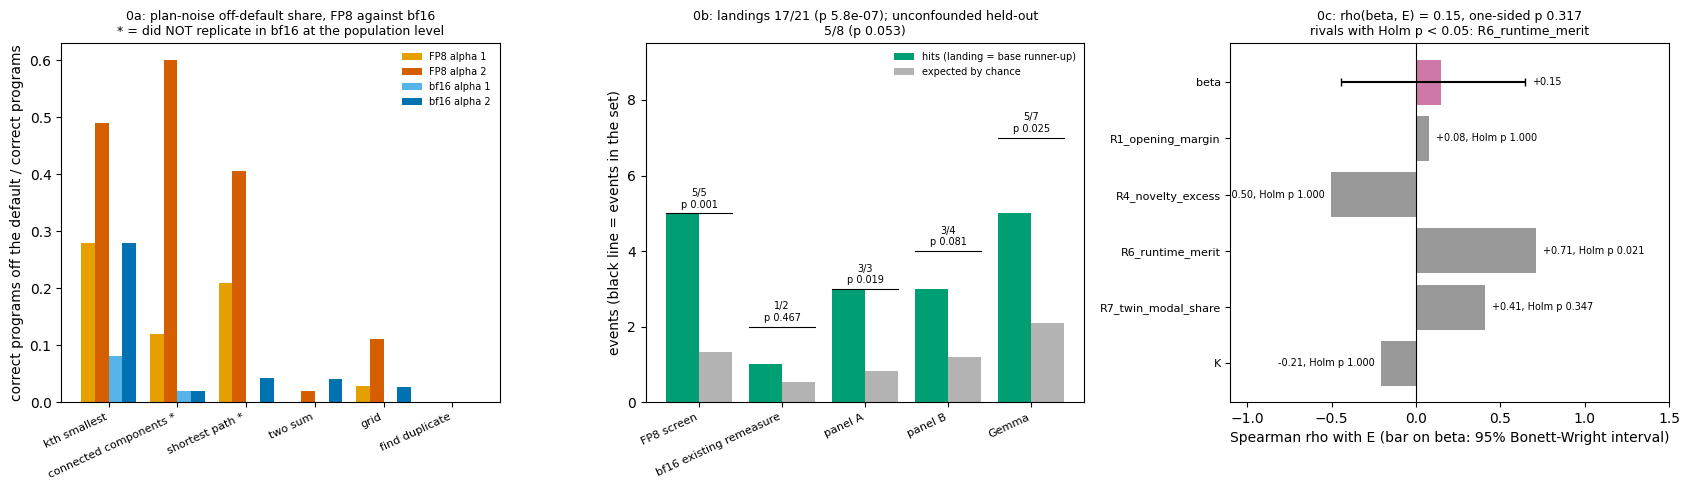

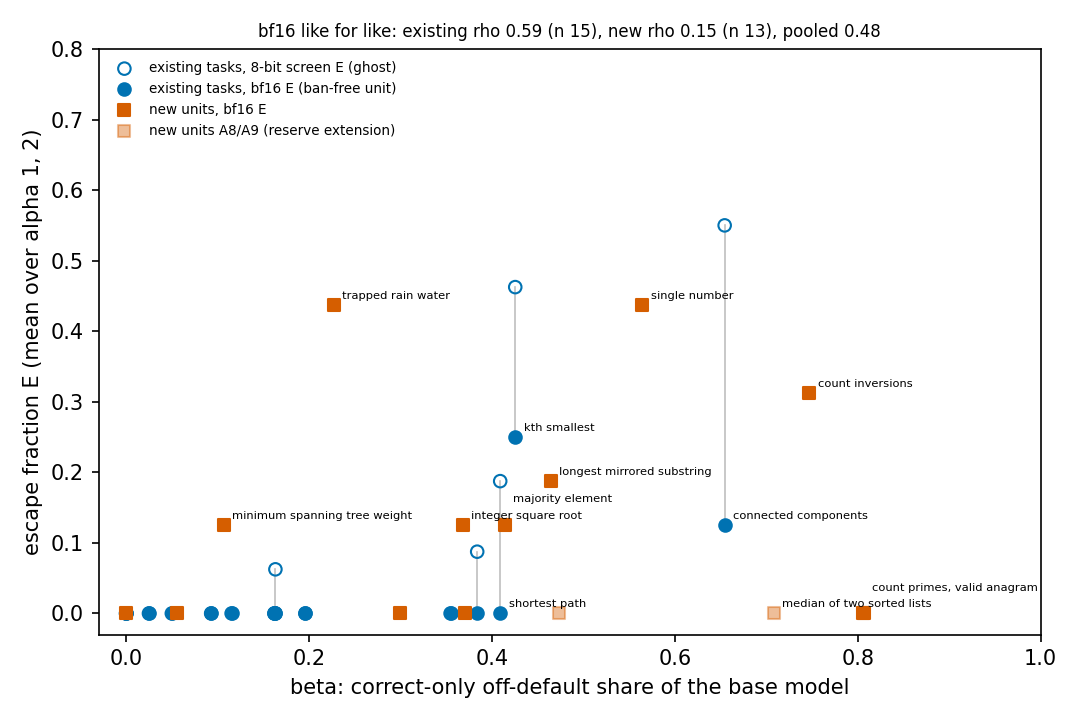

In [33]:
%matplotlib inline
# a5_figure (stage 0a) switched matplotlib to the Agg backend; the magic above turns inline plots back on.
pt = R["0a"]["A2"]["per_task"]
tasks = DECISIVE + ["T06"]
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# (a) 0a: correct-only off-default share per task, both engines, alpha 1 and 2
ax = axes[0]
xs = np.arange(len(tasks))
for j, (eng, a, lab, col) in enumerate([("fp8", "1.0", "FP8 alpha 1", "#E69F00"), ("fp8", "2.0", "FP8 alpha 2", "#D55E00"),
                                        ("bf16", "1.0", "bf16 alpha 1", "#56B4E9"), ("bf16", "2.0", "bf16 alpha 2", "#0072B2")]):
    ax.bar(xs + (j - 1.5) * 0.2, [pt[t][eng][a]["share_cor"] or 0.0 for t in tasks], 0.2, label=lab, color=col)
ax.set_xticks(xs)
ax.set_xticklabels([TNAME[t] + (" *" if pt[t]["tag"].startswith("did NOT") else "") for t in tasks],
                   rotation=25, ha="right", fontsize=8)
ax.set_ylabel("correct programs off the default / correct programs")
ax.set_title("0a: plan-noise off-default share, FP8 against bf16\n* = did NOT replicate in bf16 at the population level",
             fontsize=9)
ax.legend(fontsize=7, frameon=False)

# (b) 0b: landing hits per set against the number expected by chance
ax = axes[1]
tally = R["0b"]["tally"]
sets = [s for s in tally if s != "all"]
xs = np.arange(len(sets))
ax.bar(xs - 0.2, [tally[s]["hits"] for s in sets], 0.4, label="hits (landing = base runner-up)", color="#009E73")
ax.bar(xs + 0.2, [tally[s]["expected"] for s in sets], 0.4, label="expected by chance", color="0.7")
for i, s in enumerate(sets):
    ax.plot([i - 0.4, i + 0.4], [tally[s]["events"]] * 2, color="k", lw=0.8)
    ax.text(i, tally[s]["events"] + 0.15, f"{tally[s]['hits']}/{tally[s]['events']}\np {fmtp(tally[s]['pb_p'])}",
            ha="center", fontsize=7)
ax.set_xticks(xs)
ax.set_xticklabels(sets, rotation=25, ha="right", fontsize=8)
ax.set_ylim(0, max(tally[s]["events"] for s in sets) + 2.5)
ax.set_ylabel("events (black line = events in the set)")
cp = R["0b"]["confound"]["pooled"]
ax.set_title(f"0b: landings {tally['all']['hits']}/{tally['all']['events']} (p {fmtp(tally['all']['pb_p'])}); "
             f"unconfounded held-out\n{cp['hits']}/{cp['n']} (p {fmtp(cp['pb_p'])})", fontsize=9)
ax.legend(fontsize=7, frameon=False, loc="upper right")

# (c) 0c: Spearman rho with the escape fraction E, beta against the rival predictors (13 new units)
ax = axes[2]
c = R["0c"]
names = ["beta"] + list(c["rivals"])
rhos = [c["rho"]] + [v["rho_with_E"] for v in c["rivals"].values()]
holm = [None] + [v["holm_p"] for v in c["rivals"].values()]
ys = np.arange(len(names))[::-1]
ax.barh(ys, rhos, color=["#CC79A7"] + ["0.6"] * len(c["rivals"]))
lo, hi = c["ci"]["bonett_wright"]
ax.errorbar([c["rho"]], [ys[0]], xerr=[[c["rho"] - lo], [hi - c["rho"]]], fmt="none", ecolor="k", capsize=3)
for y, r_, h_ in zip(ys, rhos, holm):
    x_ = max(r_, hi) if h_ is None else r_  # beta's label goes past the end of its interval bar
    ax.text(x_ + (0.04 if x_ >= 0 else -0.04), y, f"{r_:+.2f}" + (f", Holm p {fmtp(h_)}" if h_ is not None else ""),
            va="center", ha="left" if x_ >= 0 else "right", fontsize=7)
ax.axvline(0, color="k", lw=0.8)
ax.set_yticks(ys)
ax.set_yticklabels(names, fontsize=8)
ax.set_xlim(-1.1, 1.5)
ax.set_xlabel("Spearman rho with E (bar on beta: 95% Bonett-Wright interval)")
surv = [k for k, v in c["rivals"].items() if v["holm_p"] < 0.05]
ax.set_title(f"0c: rho(beta, E) = {c['rho']:.2f}, one-sided p {fmtp(c['perm']['p'])}\n"
             f"rivals with Holm p < 0.05: {', '.join(surv) if surv else 'none'}", fontsize=9)
fig.tight_layout()
plt.show()

# The like-for-like figure exactly as a5_figure saved it (stage 0a, A5)
display(Image(filename=str(C.FIGURES / "fig_beta_escape_l4l.png")))